In [2]:
import sys
import pandas, sklearn, lightgbm, xgboost, catboost

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score


In [3]:
import kagglehub

kagglehub.login()

In [4]:
from pathlib import Path

import kagglehub
import pandas as pd

path = Path(kagglehub.competition_download("playground-series-s6e11"))
print("Path to competition files:", path)
print([file.name for file in path.iterdir()])

train = pd.read_csv(path / "train.csv")
test = pd.read_csv(path / "test.csv")
sample_sub = pd.read_csv(path / "sample_submission.csv")

print("train:", train.shape)
print("test:", test.shape)
print("sample:", sample_sub.shape)

Path to competition files: C:\Users\user\.cache\kagglehub\competitions\playground-series-s6e11
['sample_submission.csv', 'test.csv', 'train.csv']
train: (699960, 26)
test: (299984, 25)
sample: (299984, 2)


In [5]:
import shutil

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

for name in ["train.csv", "test.csv", "sample_submission.csv"]:
    shutil.copy2(path / name, data_dir / name)

print([file.name for file in data_dir.iterdir()])

['sample_submission.csv', 'test.csv', 'train.csv']


In [6]:

TARGET = "is_fraud"
ID_COL = "id"

train[TARGET] = train[TARGET].astype(int)
FEATURES = [c for c in test.columns if c != ID_COL]
BOOL_COLS = train[FEATURES].select_dtypes(include="bool").columns.tolist()
NUM_COLS = train[FEATURES].select_dtypes(include="number").columns.tolist()
CAT_COLS = [c for c in FEATURES if c not in NUM_COLS + BOOL_COLS]

print("Train:", train.shape, "| Test:", test.shape, "| Sample:", sample_sub.shape)
print(f"Features: {len(NUM_COLS)} numeric, {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean")
print(f"Fraud: {train[TARGET].sum():,} rows ({train[TARGET].mean():.2%})")
print("Missing values:", train[FEATURES].isna().sum().sum() + test[FEATURES].isna().sum().sum())
print("Duplicate rows:", train[FEATURES].duplicated().sum())
print("Test ids match sample:", set(test[ID_COL]) == set(sample_sub[ID_COL]))

Train: (699960, 26) | Test: (299984, 25) | Sample: (299984, 2)
Features: 13 numeric, 5 categorical, 6 boolean
Fraud: 11,689 rows (1.67%)
Missing values: 0
Duplicate rows: 0
Test ids match sample: True


                         feature     auc  strength
0            merchant_risk_score  0.7489    0.7489
1                 velocity_score  0.7108    0.7108
2                cvv_retry_count  0.7081    0.7081
3                    auth_method  0.6866    0.6866
4                is_new_merchant  0.6422    0.6422
5              merchant_category  0.6390    0.6390
6                   customer_age  0.6247    0.6247
7             txn_count_last_24h  0.6203    0.6203
8            ip_country_mismatch  0.5730    0.5730
9           hours_since_last_txn  0.4318    0.5682
10        is_foreign_transaction  0.5574    0.5574
11                      used_vpn  0.5502    0.5502
12                    amount_usd  0.5448    0.5448
13     billing_shipping_mismatch  0.5446    0.5446
14                prior_disputes  0.5322    0.5322
15  is_ai_generated_scam_attempt  0.5136    0.5136
16                     card_type  0.5119    0.5119
17                       channel  0.5112    0.5112
18                   device_typ

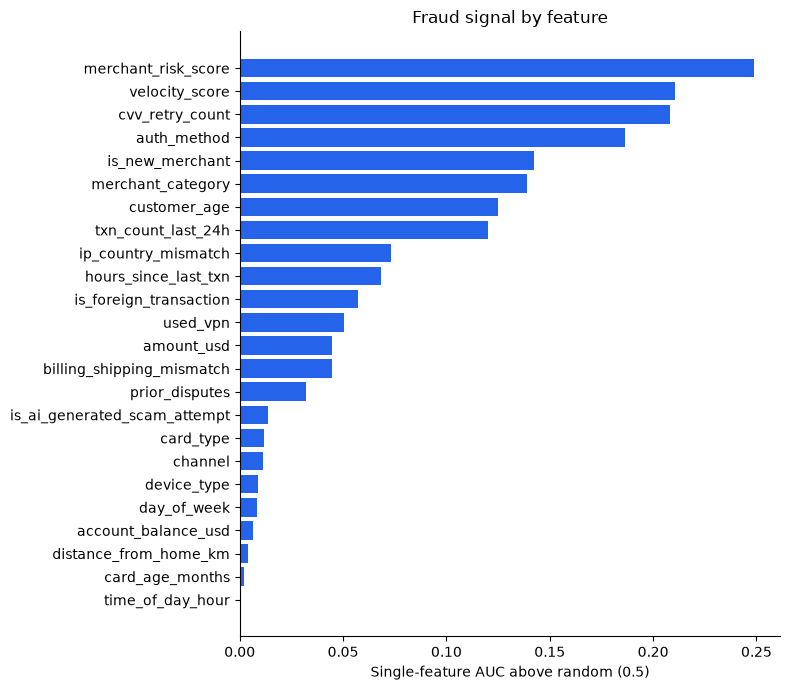

In [7]:
rows = []
for col in FEATURES:
    if col in CAT_COLS:
        values = train[col].map(train.groupby(col)[TARGET].mean())
    else:
        values = train[col].astype(float)
    auc = roc_auc_score(train[TARGET], values)
    rows.append({"feature": col, "auc": auc, "strength": max(auc, 1 - auc)})

signal = pd.DataFrame(rows).sort_values("strength", ascending=False).reset_index(drop=True)
print(signal.round(4).to_string())

chart = signal.sort_values("strength")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(chart["feature"], chart["strength"] - 0.5, color="#2563eb")
ax.set_xlabel("Single-feature AUC above random (0.5)")
ax.set_title("Fraud signal by feature")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [8]:
def fraud_rate(col):
    table = train.groupby(col, observed=True)[TARGET].agg(rows="size", frauds="sum", fraud_rate="mean")
    return table.sort_values("fraud_rate", ascending=False)

for col in CAT_COLS + BOOL_COLS + ["cvv_retry_count", "txn_count_last_24h"]:
    print(f"\n{col}")
    print(fraud_rate(col).round(4).to_string())


merchant_category
                     rows  frauds  fraud_rate
merchant_category                            
Gift Cards           9456     690      0.0730
Crypto Exchange      5285     345      0.0653
Gaming              23784    1311      0.0551
Electronics         48693    1501      0.0308
Streaming           47196    1061      0.0225
Travel              28715     534      0.0186
Utilities           42027     581      0.0138
Healthcare          35889     462      0.0129
Fuel                59880     741      0.0124
Restaurants        101360    1159      0.0114
Groceries          142578    1585      0.0111
Online Retail      155097    1719      0.0111

card_type
              rows  frauds  fraud_rate
card_type                             
Amex         45797     871      0.0190
Visa        345001    5860      0.0170
RuPay        37070     623      0.0168
Mastercard  254857    4084      0.0160
Discover     17235     251      0.0146

auth_method
                     rows  frauds  fraud

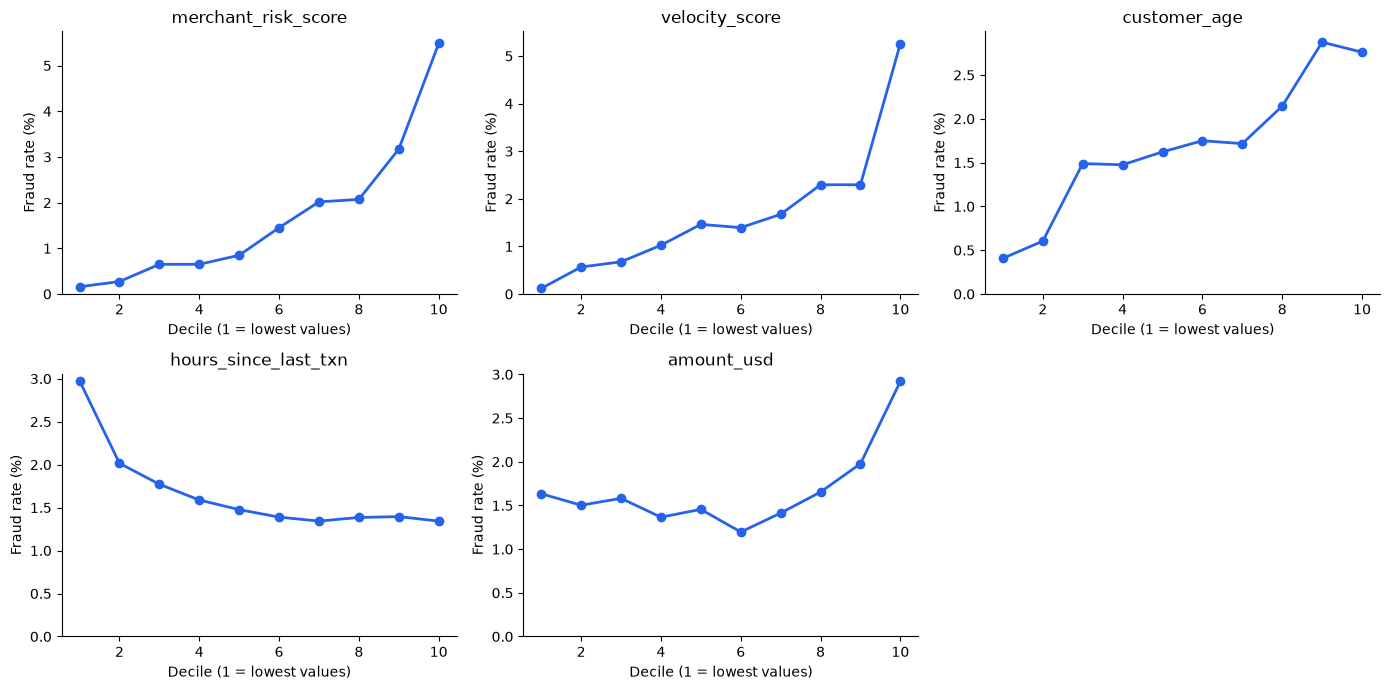

In [9]:
check_cols = ["merchant_risk_score", "velocity_score", "customer_age", "hours_since_last_txn", "amount_usd"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, check_cols):
    deciles = pd.qcut(train[col], 10, duplicates="drop")
    rate = train.groupby(deciles, observed=True)[TARGET].mean()
    ax.plot(range(1, len(rate) + 1), rate * 100, color="#2563eb", linewidth=2, marker="o")
    ax.set_title(col)
    ax.set_xlabel("Decile (1 = lowest values)")
    ax.set_ylabel("Fraud rate (%)")
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

In [10]:
drift = pd.DataFrame(
    [(col, ks_2samp(train[col], test[col]).statistic) for col in NUM_COLS],
    columns=["feature", "ks_statistic"],
).sort_values("ks_statistic", ascending=False)
print(drift.round(4).to_string(index=False))

              feature  ks_statistic
          day_of_week        0.0038
      card_age_months        0.0027
  merchant_risk_score        0.0022
distance_from_home_km        0.0020
  account_balance_usd        0.0019
     time_of_day_hour        0.0016
           amount_usd        0.0015
       velocity_score        0.0014
 hours_since_last_txn        0.0014
       prior_disputes        0.0008
         customer_age        0.0008
   txn_count_last_24h        0.0007
      cvv_retry_count        0.0001


In [11]:
from pathlib import Path
import time

import catboost as cb
import lightgbm as lgb
import xgboost as xgb
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold

SEED = 42
N_FOLDS = 5
OOF_DIR = Path("oof")
SUB_DIR = Path("submissions")
OOF_DIR.mkdir(exist_ok=True)
SUB_DIR.mkdir(exist_ok=True)

X = train[FEATURES].copy()
X_test = test[FEATURES].copy()
y = train[TARGET].copy()

X[BOOL_COLS] = X[BOOL_COLS].astype(int)
X_test[BOOL_COLS] = X_test[BOOL_COLS].astype(int)

for col in CAT_COLS:
    categories = sorted(set(X[col]) | set(X_test[col]))
    X[col] = pd.Categorical(X[col], categories=categories)
    X_test[col] = pd.Categorical(X_test[col], categories=categories)

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X, y))

results = {}
def run_cv(name, fit_model, force=False):
    oof_path = OOF_DIR / f"{name}_oof.npy"
    test_path = OOF_DIR / f"{name}_test.npy"

    if oof_path.exists() and test_path.exists() and not force:
        oof = np.load(oof_path)
        test_pred = np.load(test_path)
        if len(oof) != len(X) or len(test_pred) != len(X_test):
            raise ValueError(f"Saved {name} predictions do not match the data")

        cv_score = roc_auc_score(y, oof)
        results[name] = {"oof": oof, "test": test_pred, "cv": cv_score}
        print(f"{name}: loaded saved predictions | CV AUC {cv_score:.5f}")
        return

    start = time.time()
    oof = np.zeros(len(X))
    test_pred = np.zeros(len(X_test))
    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(FOLDS, 1):
        model, best_iter = fit_model(
            X.iloc[train_idx], y.iloc[train_idx],
            X.iloc[valid_idx], y.iloc[valid_idx],
        )
        oof[valid_idx] = model.predict_proba(X.iloc[valid_idx])[:, 1]
        test_pred += model.predict_proba(X_test)[:, 1] / N_FOLDS

        score = roc_auc_score(y.iloc[valid_idx], oof[valid_idx])
        fold_scores.append(score)
        print(f"{name} fold {fold}: AUC {score:.5f} | trees {best_iter}")

    cv_score = roc_auc_score(y, oof)
    minutes = (time.time() - start) / 60
    print(f"{name} CV AUC: {cv_score:.5f} | fold std {np.std(fold_scores):.5f} | {minutes:.1f} min")

    np.save(oof_path, oof)
    np.save(test_path, test_pred)
    results[name] = {"oof": oof, "test": test_pred, "cv": cv_score}

In [12]:
def fit_lgb(X_train, y_train, X_valid, y_valid):
    model = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=3000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=SEED,
        verbose=-1,
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model, model.best_iteration_

run_cv("lgb", fit_lgb)

lgb: loaded saved predictions | CV AUC 0.94663


In [13]:
def fit_xgb(X_train, y_train, X_valid, y_valid):
    model = xgb.XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        enable_categorical=True,
        n_estimators=3000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        early_stopping_rounds=100,
        random_state=SEED,
    )
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    return model, model.best_iteration

run_cv("xgb", fit_xgb)

xgb: loaded saved predictions | CV AUC 0.94650


In [14]:
def fit_cat(X_train, y_train, X_valid, y_valid):
    model = cb.CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        iterations=3000,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=3,
        early_stopping_rounds=100,
        random_seed=SEED,
        verbose=False,
    )
    model.fit(
        X_train, y_train,
        cat_features=CAT_COLS,
        eval_set=(X_valid, y_valid),
        use_best_model=True,
    )
    return model, model.get_best_iteration()

run_cv("cat", fit_cat)

cat: loaded saved predictions | CV AUC 0.94603


In [15]:
for name, result in results.items():
    print(f"{name}: {result['cv']:.5f}")

names = list(results)
blend_oof = np.mean([rankdata(results[name]["oof"]) / len(y) for name in names], axis=0)
blend_test = np.mean([rankdata(results[name]["test"]) / len(X_test) for name in names], axis=0)
print(f"blend: {roc_auc_score(y, blend_oof):.5f}")

if len(blend_test) != len(sample_sub) or not np.isfinite(blend_test).all():
    raise ValueError("Predictions do not match the sample submission")

submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: blend_test})
submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()

file_path = SUB_DIR / "baseline_blend.csv"
submission.to_csv(file_path, index=False)
print(file_path, submission.shape)
print(submission.head())

lgb: 0.94663
xgb: 0.94650
cat: 0.94603
blend: 0.94701
submissions\baseline_blend.csv (299984, 2)
       id  is_fraud
0  699960  0.118889
1  699961  0.063671
2  699962  0.962559
3  699963  0.427131
4  699964  0.434861


In [16]:
results = {}

for name in ["lgb", "xgb", "cat"]:
    oof = np.load(OOF_DIR / f"{name}_oof.npy")
    test_pred = np.load(OOF_DIR / f"{name}_test.npy")
    results[name] = {"oof": oof, "test": test_pred, "cv": roc_auc_score(y, oof)}
    print(f"{name}: {results[name]['cv']:.5f}")

lgb: 0.94663
xgb: 0.94650
cat: 0.94603


In [17]:
FLAG_COLS = [
    "is_foreign_transaction", "is_new_merchant", "used_vpn",
    "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt",
]
COUNT_COLS = ["amount_usd", "account_balance_usd", "hours_since_last_txn", "distance_from_home_km"]

full = pd.concat([train[FEATURES], test[FEATURES]], ignore_index=True)

def add_features(df):
    df = df.copy()
    df["flag_count"] = df[FLAG_COLS].astype(int).sum(axis=1)
    df["risk_signals"] = (
        df["flag_count"]
        + (df["cvv_retry_count"] > 0).astype(int)
        + (df["auth_method"] == "No Authentication").astype(int)
    )
    df["risk_x_velocity"] = df["merchant_risk_score"] * df["velocity_score"]
    df["risk_x_amount"] = df["merchant_risk_score"] * np.log1p(df["amount_usd"])
    df["amount_to_balance"] = df["amount_usd"] / df["account_balance_usd"]
    df["txn_per_hour"] = df["txn_count_last_24h"] / (df["hours_since_last_txn"] + 0.1)
    for col in COUNT_COLS:
        df[f"{col}_count"] = df[col].map(full[col].value_counts())
    return df

X_fe = add_features(X)
X_test_fe = add_features(X_test)
NEW_COLS = [c for c in X_fe.columns if c not in X.columns]

print(f"{len(NEW_COLS)} new features:", NEW_COLS)
print("Missing values:", X_fe[NEW_COLS].isna().sum().sum(), X_test_fe[NEW_COLS].isna().sum().sum())
for col in NEW_COLS:
    print(f"{col:30s} AUC {roc_auc_score(y, X_fe[col]):.4f}")

10 new features: ['flag_count', 'risk_signals', 'risk_x_velocity', 'risk_x_amount', 'amount_to_balance', 'txn_per_hour', 'amount_usd_count', 'account_balance_usd_count', 'hours_since_last_txn_count', 'distance_from_home_km_count']
Missing values: 0 0
flag_count                     AUC 0.7513
risk_signals                   AUC 0.8642
risk_x_velocity                AUC 0.7981
risk_x_amount                  AUC 0.7050
amount_to_balance              AUC 0.5344
txn_per_hour                   AUC 0.6166
amount_usd_count               AUC 0.4466
account_balance_usd_count      AUC 0.4899
hours_since_last_txn_count     AUC 0.5241
distance_from_home_km_count    AUC 0.4916


In [18]:
X_base, X_test_base = X, X_test
X, X_test = X_fe, X_test_fe

run_cv("lgb_fe", fit_lgb)

X, X_test = X_base, X_test_base

lgb_fe: loaded saved predictions | CV AUC 0.94665


In [19]:
def compare(base_name, new_name):
    rows = []
    for fold, (_, valid_idx) in enumerate(FOLDS, 1):
        base = roc_auc_score(y.iloc[valid_idx], results[base_name]["oof"][valid_idx])
        new = roc_auc_score(y.iloc[valid_idx], results[new_name]["oof"][valid_idx])
        rows.append({"fold": fold, "base": base, "new": new, "gain": new - base})

    table = pd.DataFrame(rows)
    print(table.round(5).to_string(index=False))
    print(f"\nOverall: {results[base_name]['cv']:.5f} -> {results[new_name]['cv']:.5f} "
          f"({results[new_name]['cv'] - results[base_name]['cv']:+.5f})")
    print(f"Folds improved: {(table['gain'] > 0).sum()} of {len(table)}")

compare("lgb", "lgb_fe")

 fold    base     new     gain
    1 0.94496 0.94506  0.00010
    2 0.94849 0.94820 -0.00029
    3 0.95129 0.95109 -0.00020
    4 0.94681 0.94719  0.00038
    5 0.94184 0.94205  0.00022

Overall: 0.94663 -> 0.94665 (+0.00003)
Folds improved: 3 of 5


In [20]:
orig_path = Path(kagglehub.dataset_download("uditjain13/credit-card-fraud-detection-2026"))
print([file.name for file in orig_path.iterdir()])

orig = pd.read_csv(next(orig_path.glob("*.csv")))
print(orig.shape)
print("Missing from original:", sorted(set(FEATURES) - set(orig.columns)))
print("Extra in original:", sorted(set(orig.columns) - set(FEATURES) - {TARGET}))
if TARGET in orig.columns:
    print("Fraud rate:", orig[TARGET].mean())
print(orig.head())

['credit_card_fraud_2026.csv']
(20000, 26)
Missing from original: []
Extra in original: ['transaction_id']
Fraud rate: 0.01695
   transaction_id  amount_usd merchant_category   card_type  \
0               1       42.86       Restaurants        Visa   
1               2        4.75     Online Retail  Mastercard   
2               3       77.18         Groceries  Mastercard   
3               4        1.69         Streaming        Visa   
4               5      261.68            Travel        Visa   

         auth_method channel    device_type  is_foreign_transaction  \
0                OTP  Online  Android Phone                   False   
1          3D Secure  Online  Android Phone                   False   
2          3D Secure  Online            Mac                   False   
3  No Authentication     POS  Android Phone                   False   
4          3D Secure  In-App         iPhone                   False   

   hours_since_last_txn  txn_count_last_24h  ...  ip_country_mismat

In [21]:
X_orig = orig[FEATURES].copy()
y_orig = orig[TARGET].astype(int)

X_orig[BOOL_COLS] = X_orig[BOOL_COLS].astype(int)
for col in CAT_COLS:
    X_orig[col] = pd.Categorical(X_orig[col], categories=X[col].cat.categories)

print(X_orig.shape)
print("Unknown categories:", X_orig[CAT_COLS].isna().sum().sum())
print("Column types match:", (X_orig.dtypes == X.dtypes).all())

(20000, 24)
Unknown categories: 0
Column types match: True


In [22]:
def with_orig(fit_model):
    def fit(X_train, y_train, X_valid, y_valid):
        X_train = pd.concat([X_train, X_orig], ignore_index=True)
        y_train = pd.concat([y_train, y_orig], ignore_index=True)
        return fit_model(X_train, y_train, X_valid, y_valid)
    return fit

run_cv("lgb_orig", with_orig(fit_lgb))
compare("lgb", "lgb_orig")

lgb_orig: loaded saved predictions | CV AUC 0.94637
 fold    base     new     gain
    1 0.94496 0.94440 -0.00056
    2 0.94849 0.94853  0.00004
    3 0.95129 0.95098 -0.00032
    4 0.94681 0.94660 -0.00021
    5 0.94184 0.94150 -0.00033

Overall: 0.94663 -> 0.94637 (-0.00026)
Folds improved: 1 of 5


In [23]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

tune_train_idx, tune_valid_idx = FOLDS[0]
X_tr, y_tr = X.iloc[tune_train_idx], y.iloc[tune_train_idx]
X_va, y_va = X.iloc[tune_valid_idx], y.iloc[tune_valid_idx]

def objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 500, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    model = lgb.LGBMClassifier(
        objective="binary", n_estimators=3000, learning_rate=0.05,
        subsample_freq=1, random_state=SEED, verbose=-1, **params,
    )
    model.fit(
        X_tr, y_tr, eval_X=X_va, eval_y=y_va, eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40, timeout=1200, show_progress_bar=True)

print(f"Best fold 1 AUC: {study.best_value:.5f} (baseline 0.94496)")
print("Best settings:", study.best_params)

  0%|          | 0/40 [00:00<?, ?it/s]

[W 2026-11-11 12:28:14,335] Trial 12 failed with parameters: {'num_leaves': 26, 'max_depth': 3, 'min_child_samples': 156, 'subsample': 0.7197221649916247, 'colsample_bytree': 0.4213463095016122, 'reg_alpha': 0.10334199726160251, 'reg_lambda': 6.505452555879942} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\user\Desktop\KaggleFraudDetection\.venv\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\user\AppData\Local\Temp\ipykernel_61316\568019359.py", line 23, in objective
    model.fit(
    ~~~~~~~~~^
        X_tr, y_tr, eval_X=X_va, eval_y=y_va, eval_metric="auc",
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        callbacks=[lgb.early_stopping(100, verbose=False)],
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "c:\Users\user\Desktop\KaggleFraudDetection\.venv\Lib\site-packages\lightgbm\sklearn.py", line 1

KeyboardInterrupt: 

In [ ]:
BEST_LGB = study.best_params

def fit_lgb_tuned(X_train, y_train, X_valid, y_valid):
    model = lgb.LGBMClassifier(
        objective="binary", n_estimators=5000, learning_rate=0.02,
        subsample_freq=1, random_state=SEED, verbose=-1, **BEST_LGB,
    )
    model.fit(
        X_train, y_train, eval_X=X_valid, eval_y=y_valid, eval_metric="auc",
        callbacks=[lgb.early_stopping(200, verbose=False)],
    )
    return model, model.best_iteration_

run_cv("lgb_tuned", fit_lgb_tuned)
compare("lgb", "lgb_tuned")

lgb_tuned fold 1: AUC 0.94607 | trees 2744
lgb_tuned fold 2: AUC 0.94948 | trees 3411
lgb_tuned fold 3: AUC 0.95206 | trees 2769
lgb_tuned fold 4: AUC 0.94753 | trees 2259
lgb_tuned fold 5: AUC 0.94276 | trees 3308
lgb_tuned CV AUC: 0.94754 | fold std 0.00314 | 6.0 min
 fold    base     new    gain
    1 0.94496 0.94607 0.00111
    2 0.94849 0.94948 0.00099
    3 0.95129 0.95206 0.00076
    4 0.94681 0.94753 0.00073
    5 0.94184 0.94276 0.00092

Overall: 0.94663 -> 0.94754 (+0.00091)
Folds improved: 5 of 5


In [ ]:
def blend(names):
    oof = np.mean([rankdata(results[n]["oof"]) / len(y) for n in names], axis=0)
    test_pred = np.mean([rankdata(results[n]["test"]) / len(X_test) for n in names], axis=0)
    return roc_auc_score(y, oof), test_pred

candidates = [
    ["lgb_tuned"],
    ["lgb_tuned", "xgb"],
    ["lgb_tuned", "cat"],
    ["lgb_tuned", "xgb", "cat"],
]

scores = {}
for names in candidates:
    score, test_pred = blend(names)
    scores[" + ".join(names)] = (score, test_pred)
    print(f"{' + '.join(names):25s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
file_path = SUB_DIR / "tuned_blend.csv"
submission.to_csv(file_path, index=False)
print(file_path, submission.shape)

lgb_tuned                 0.94754
lgb_tuned + xgb           0.94735
lgb_tuned + cat           0.94720
lgb_tuned + xgb + cat     0.94726

Best: lgb_tuned (0.94754)
submissions\tuned_blend.csv (299984, 2)


In [ ]:
def objective_xgb(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 5, log=True),
    }
    model = xgb.XGBClassifier(
        objective="binary:logistic", eval_metric="auc", tree_method="hist",
        enable_categorical=True, n_estimators=3000, learning_rate=0.05,
        early_stopping_rounds=100, random_state=SEED, **params,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])

study_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(objective_xgb, n_trials=40, timeout=1200, show_progress_bar=True)

print(f"Best fold 1 AUC: {study_xgb.best_value:.5f} (baseline 0.94460)")
print("Best settings:", study_xgb.best_params)

  0%|          | 0/40 [00:00<?, ?it/s]

Best fold 1 AUC: 0.94631 (baseline 0.94460)
Best settings: {'max_depth': 3, 'min_child_weight': 14.706743886292879, 'subsample': 0.6407045938964151, 'colsample_bytree': 0.31219652419341526, 'reg_alpha': 0.03122663557658015, 'reg_lambda': 0.0034277848054123285, 'gamma': 1.014121266020497}


In [ ]:
BEST_XGB = study_xgb.best_params

def fit_xgb_tuned(X_train, y_train, X_valid, y_valid):
    model = xgb.XGBClassifier(
        objective="binary:logistic", eval_metric="auc", tree_method="hist",
        enable_categorical=True, n_estimators=5000, learning_rate=0.02,
        early_stopping_rounds=200, random_state=SEED, **BEST_XGB,
    )
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    return model, model.best_iteration

run_cv("xgb_tuned", fit_xgb_tuned)
compare("xgb", "xgb_tuned")

xgb_tuned fold 1: AUC 0.94592 | trees 3255
xgb_tuned fold 2: AUC 0.94907 | trees 2484
xgb_tuned fold 3: AUC 0.95211 | trees 2318
xgb_tuned fold 4: AUC 0.94755 | trees 2360
xgb_tuned fold 5: AUC 0.94321 | trees 3456
xgb_tuned CV AUC: 0.94749 | fold std 0.00298 | 9.9 min
 fold    base     new    gain
    1 0.94460 0.94592 0.00132
    2 0.94842 0.94907 0.00064
    3 0.95114 0.95211 0.00097
    4 0.94657 0.94755 0.00098
    5 0.94186 0.94321 0.00136

Overall: 0.94650 -> 0.94749 (+0.00099)
Folds improved: 5 of 5


In [ ]:
def blend(names):
    oof = np.mean([rankdata(results[n]["oof"]) / len(y) for n in names], axis=0)
    test_pred = np.mean([rankdata(results[n]["test"]) / len(X_test) for n in names], axis=0)
    return roc_auc_score(y, oof), test_pred

candidates = [
    ["lgb_tuned"],
    ["xgb_tuned"],
    ["lgb_tuned", "xgb_tuned"],
    ["lgb_tuned", "xgb_tuned", "cat"],
]

scores = {}
for names in candidates:
    score, test_pred = blend(names)
    scores[" + ".join(names)] = (score, test_pred)
    print(f"{' + '.join(names):30s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
file_path = SUB_DIR / "tuned_blend_v2.csv"
submission.to_csv(file_path, index=False)
print(file_path, submission.shape)

lgb_tuned                      0.94754
xgb_tuned                      0.94749
lgb_tuned + xgb_tuned          0.94765
lgb_tuned + xgb_tuned + cat    0.94744

Best: lgb_tuned + xgb_tuned (0.94765)
submissions\tuned_blend_v2.csv (299984, 2)


In [ ]:
base_cat_fold1 = roc_auc_score(y_va, results["cat"]["oof"][tune_valid_idx])

def objective_cat(trial):
    params = {
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.1, 10, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 1),
    }
    model = cb.CatBoostClassifier(
        loss_function="Logloss", eval_metric="AUC", iterations=3000,
        learning_rate=0.1, early_stopping_rounds=100, metric_period=50,
        random_seed=SEED, verbose=False, **params,
    )
    model.fit(X_tr, y_tr, cat_features=CAT_COLS, eval_set=(X_va, y_va), use_best_model=True)
    return roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])

study_cat = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_cat.optimize(objective_cat, n_trials=30, timeout=1200, show_progress_bar=True)

print(f"Best fold 1 AUC: {study_cat.best_value:.5f} (baseline {base_cat_fold1:.5f})")
print("Best settings:", study_cat.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Best fold 1 AUC: 0.94492 (baseline 0.94422)
Best settings: {'depth': 4, 'l2_leaf_reg': 1.6998978382700767, 'random_strength': 0.13066739238053282, 'bagging_temperature': 0.8661761457749352}


In [ ]:
BEST_CAT = study_cat.best_params

def fit_cat_tuned(X_train, y_train, X_valid, y_valid):
    model = cb.CatBoostClassifier(
        loss_function="Logloss", eval_metric="AUC", iterations=5000,
        learning_rate=0.05, early_stopping_rounds=200, metric_period=50,
        random_seed=SEED, verbose=False, **BEST_CAT,
    )
    model.fit(X_train, y_train, cat_features=CAT_COLS, eval_set=(X_valid, y_valid), use_best_model=True)
    return model, model.get_best_iteration()

run_cv("cat_tuned", fit_cat_tuned)
compare("cat", "cat_tuned")

cat_tuned fold 1: AUC 0.94530 | trees 2796


cat_tuned fold 2: AUC 0.94847 | trees 2584


cat_tuned fold 3: AUC 0.95121 | trees 1683


cat_tuned fold 4: AUC 0.94674 | trees 2542


cat_tuned fold 5: AUC 0.94252 | trees 3206
cat_tuned CV AUC: 0.94678 | fold std 0.00292 | 49.5 min
 fold    base     new    gain
    1 0.94422 0.94530 0.00107
    2 0.94745 0.94847 0.00102
    3 0.95061 0.95121 0.00059
    4 0.94622 0.94674 0.00051
    5 0.94193 0.94252 0.00059

Overall: 0.94603 -> 0.94678 (+0.00075)
Folds improved: 5 of 5


In [ ]:
def blend(names, weights=None):
    if weights is None:
        weights = [1] * len(names)
    weights = np.array(weights) / np.sum(weights)
    oof = sum(w * rankdata(results[n]["oof"]) / len(y) for n, w in zip(names, weights))
    test_pred = sum(w * rankdata(results[n]["test"]) / len(X_test) for n, w in zip(names, weights))
    return roc_auc_score(y, oof), test_pred

names3 = ["lgb_tuned", "xgb_tuned", "cat_tuned"]
candidates = {
    "lgb_tuned + xgb_tuned": (["lgb_tuned", "xgb_tuned"], None),
    "all 3, equal": (names3, None),
}
for w_cat in [0.1, 0.2, 0.3]:
    w_rest = (1 - w_cat) / 2
    candidates[f"all 3, cat weight {w_cat}"] = (names3, [w_rest, w_rest, w_cat])

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:28s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
file_path = SUB_DIR / "tuned_blend_v3.csv"
submission.to_csv(file_path, index=False)
print(file_path, submission.shape)

lgb_tuned + xgb_tuned        0.94765
all 3, equal                 0.94763
all 3, cat weight 0.1        0.94767
all 3, cat weight 0.2        0.94767
all 3, cat weight 0.3        0.94764

Best: all 3, cat weight 0.1 (0.94767)
submissions\tuned_blend_v3.csv (299984, 2)


In [ ]:
XGB_D2 = {**BEST_XGB, "max_depth": 2}

def fit_xgb_d2(X_train, y_train, X_valid, y_valid):
    model = xgb.XGBClassifier(
        objective="binary:logistic", eval_metric="auc", tree_method="hist",
        enable_categorical=True, n_estimators=10000, learning_rate=0.02,
        early_stopping_rounds=200, random_state=SEED, **XGB_D2,
    )
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    return model, model.best_iteration

run_cv("xgb_d2", fit_xgb_d2)
compare("xgb_tuned", "xgb_d2")

xgb_d2 fold 1: AUC 0.94597 | trees 5337
xgb_d2 fold 2: AUC 0.94932 | trees 5450
xgb_d2 fold 3: AUC 0.95249 | trees 5560
xgb_d2 fold 4: AUC 0.94730 | trees 3103
xgb_d2 fold 5: AUC 0.94316 | trees 4519
xgb_d2 CV AUC: 0.94762 | fold std 0.00314 | 15.3 min
 fold    base     new     gain
    1 0.94592 0.94597  0.00005
    2 0.94907 0.94932  0.00025
    3 0.95211 0.95249  0.00038
    4 0.94755 0.94730 -0.00024
    5 0.94321 0.94316 -0.00006

Overall: 0.94749 -> 0.94762 (+0.00013)
Folds improved: 3 of 5


In [ ]:
candidates = {
    "current best (v3)": (["lgb_tuned", "xgb_tuned", "cat_tuned"], [0.45, 0.45, 0.1]),
    "lgb + xgb_d2": (["lgb_tuned", "xgb_d2"], None),
    "lgb + xgb + xgb_d2": (["lgb_tuned", "xgb_tuned", "xgb_d2"], None),
    "lgb + xgb + xgb_d2 + cat": (["lgb_tuned", "xgb_tuned", "xgb_d2", "cat_tuned"], [0.3, 0.3, 0.3, 0.1]),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:28s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_name != "current best (v3)":
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "tuned_blend_v4.csv"
    submission.to_csv(file_path, index=False)
    print(file_path, submission.shape)

current best (v3)            0.94767
lgb + xgb_d2                 0.94772
lgb + xgb + xgb_d2           0.94770
lgb + xgb + xgb_d2 + cat     0.94772

Best: lgb + xgb + xgb_d2 + cat (0.94772)
submissions\tuned_blend_v4.csv (299984, 2)


In [ ]:
print(study.best_params)

{'num_leaves': 29, 'max_depth': 3, 'min_child_samples': 321, 'subsample': 0.707506411598124, 'colsample_bytree': 0.4579202474702105, 'reg_alpha': 0.37796609591244756, 'reg_lambda': 7.032091957692864}


In [25]:
BEST_LGB = {
    "num_leaves": 29, "max_depth": 3, "min_child_samples": 321,
    "subsample": 0.707506411598124, "colsample_bytree": 0.4579202474702105,
    "reg_alpha": 0.37796609591244756, "reg_lambda": 7.032091957692864,
}
XGB_D2 = {**BEST_XGB, "max_depth": 2}

def make_fit_lgb(seed, params, n_trees=5000):
    def fit(X_train, y_train, X_valid, y_valid):
        model = lgb.LGBMClassifier(
            objective="binary", n_estimators=n_trees, learning_rate=0.02,
            subsample_freq=1, random_state=seed, verbose=-1, **params,
        )
        model.fit(
            X_train, y_train, eval_X=X_valid, eval_y=y_valid, eval_metric="auc",
            callbacks=[lgb.early_stopping(200, verbose=False)],
        )
        return model, model.best_iteration_
    return fit

def make_fit_xgb(seed, params, n_trees=5000):
    def fit(X_train, y_train, X_valid, y_valid):
        model = xgb.XGBClassifier(
            objective="binary:logistic", eval_metric="auc", tree_method="hist",
            enable_categorical=True, n_estimators=n_trees, learning_rate=0.02,
            early_stopping_rounds=200, random_state=seed, **params,
        )
        model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
        return model, model.best_iteration
    return fit

In [ ]:
LGB_D2 = {**BEST_LGB, "max_depth": 2}

run_cv("lgb_d2", make_fit_lgb(SEED, LGB_D2, n_trees=10000))
compare("lgb_tuned", "lgb_d2")

lgb_d2 fold 1: AUC 0.94593 | trees 4925
lgb_d2 fold 2: AUC 0.94951 | trees 5348
lgb_d2 fold 3: AUC 0.95220 | trees 5337
lgb_d2 fold 4: AUC 0.94755 | trees 3237
lgb_d2 fold 5: AUC 0.94305 | trees 4744
lgb_d2 CV AUC: 0.94762 | fold std 0.00311 | 9.2 min
 fold    base     new     gain
    1 0.94607 0.94593 -0.00013
    2 0.94948 0.94951  0.00003
    3 0.95206 0.95220  0.00014
    4 0.94753 0.94755  0.00001
    5 0.94276 0.94305  0.00029

Overall: 0.94754 -> 0.94762 (+0.00009)
Folds improved: 4 of 5


In [ ]:
for seed in [1, 2]:
    run_cv(f"lgb_tuned_s{seed}", make_fit_lgb(seed, BEST_LGB))
    run_cv(f"xgb_d2_s{seed}", make_fit_xgb(seed, XGB_D2, n_trees=10000))    

lgb_tuned_s1 fold 1: AUC 0.94582 | trees 2854
lgb_tuned_s1 fold 2: AUC 0.94929 | trees 3824
lgb_tuned_s1 fold 3: AUC 0.95215 | trees 3428
lgb_tuned_s1 fold 4: AUC 0.94747 | trees 2620
lgb_tuned_s1 fold 5: AUC 0.94285 | trees 3170
lgb_tuned_s1 CV AUC: 0.94749 | fold std 0.00314 | 7.0 min
xgb_d2_s1 fold 1: AUC 0.94606 | trees 4721
xgb_d2_s1 fold 2: AUC 0.94922 | trees 4268
xgb_d2_s1 fold 3: AUC 0.95216 | trees 4524
xgb_d2_s1 fold 4: AUC 0.94735 | trees 3469
xgb_d2_s1 fold 5: AUC 0.94302 | trees 4572
xgb_d2_s1 CV AUC: 0.94753 | fold std 0.00306 | 14.7 min
lgb_tuned_s2 fold 1: AUC 0.94601 | trees 3010
lgb_tuned_s2 fold 2: AUC 0.94945 | trees 2572
lgb_tuned_s2 fold 3: AUC 0.95194 | trees 2972
lgb_tuned_s2 fold 4: AUC 0.94763 | trees 2609
lgb_tuned_s2 fold 5: AUC 0.94282 | trees 3184
lgb_tuned_s2 CV AUC: 0.94752 | fold std 0.00308 | 6.1 min
xgb_d2_s2 fold 1: AUC 0.94600 | trees 5743
xgb_d2_s2 fold 2: AUC 0.94942 | trees 5069
xgb_d2_s2 fold 3: AUC 0.95230 | trees 5686
xgb_d2_s2 fold 4: AUC 0.

In [ ]:
def average_seeds(new_name, names):
    oof = np.mean([results[n]["oof"] for n in names], axis=0)
    test_pred = np.mean([results[n]["test"] for n in names], axis=0)
    results[new_name] = {"oof": oof, "test": test_pred, "cv": roc_auc_score(y, oof)}
    print(f"{new_name}: {results[new_name]['cv']:.5f}")

average_seeds("lgb_3seeds", ["lgb_tuned", "lgb_tuned_s1", "lgb_tuned_s2"])
average_seeds("xgb_d2_3seeds", ["xgb_d2", "xgb_d2_s1", "xgb_d2_s2"])

compare("lgb_tuned", "lgb_3seeds")
compare("xgb_d2", "xgb_d2_3seeds")

lgb_3seeds: 0.94761
xgb_d2_3seeds: 0.94764
 fold    base     new     gain
    1 0.94607 0.94606 -0.00000
    2 0.94948 0.94952  0.00004
    3 0.95206 0.95214  0.00008
    4 0.94753 0.94763  0.00010
    5 0.94276 0.94291  0.00015

Overall: 0.94754 -> 0.94761 (+0.00008)
Folds improved: 4 of 5
 fold    base     new     gain
    1 0.94597 0.94607  0.00010
    2 0.94932 0.94938  0.00006
    3 0.95249 0.95238 -0.00011
    4 0.94730 0.94739  0.00009
    5 0.94316 0.94312 -0.00004

Overall: 0.94762 -> 0.94764 (+0.00001)
Folds improved: 3 of 5


In [26]:
DIGIT_COLS = {
    "amount_usd": 2, "account_balance_usd": 2, "hours_since_last_txn": 2,
    "distance_from_home_km": 2, "velocity_score": 1, "merchant_risk_score": 1,
    "card_age_months": 0, "customer_age": 0,
}

def add_digits(df):
    df = df.copy()
    for col, decimals in DIGIT_COLS.items():
        as_int = np.round(df[col] * 10**decimals).astype("int64")
        n_places = len(str(int(max(X[col].max(), X_test[col].max()) * 10**decimals)))
        for place in range(n_places):
            df[f"{col}_d{place}"] = ((as_int // 10**place) % 10).astype("int8")
    return df

X_dig = add_digits(X)
X_test_dig = add_digits(X_test)
DIGIT_FEATURES = [c for c in X_dig.columns if c not in X.columns]

print(len(DIGIT_FEATURES), "digit features")
print(X_dig[["amount_usd"] + [c for c in DIGIT_FEATURES if c.startswith("amount_usd")]].head(3))

32 digit features
   amount_usd  amount_usd_d0  amount_usd_d1  amount_usd_d2  amount_usd_d3  \
0       61.16              6              1              1              6   
1       24.83              3              8              4              2   
2        6.36              6              3              6              0   

   amount_usd_d4  amount_usd_d5  
0              0              0  
1              0              0  
2              0              0  


In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_dig, X_test_dig

run_cv("lgb_dig", make_fit_lgb(SEED, BEST_LGB))

X, X_test = X_base, X_test_base
compare("lgb_tuned", "lgb_dig")

lgb_dig fold 1: AUC 0.94648 | trees 3157
lgb_dig fold 2: AUC 0.94962 | trees 3699
lgb_dig fold 3: AUC 0.95287 | trees 2774
lgb_dig fold 4: AUC 0.94824 | trees 2613
lgb_dig fold 5: AUC 0.94325 | trees 3185
lgb_dig CV AUC: 0.94805 | fold std 0.00320 | 9.4 min
 fold    base     new    gain
    1 0.94607 0.94648 0.00042
    2 0.94948 0.94962 0.00014
    3 0.95206 0.95287 0.00082
    4 0.94753 0.94824 0.00071
    5 0.94276 0.94325 0.00049

Overall: 0.94754 -> 0.94805 (+0.00051)
Folds improved: 5 of 5


In [27]:
X_dig_cat = X_dig.copy()
X_test_dig_cat = X_test_dig.copy()
for col in DIGIT_FEATURES:
    X_dig_cat[col] = pd.Categorical(X_dig_cat[col], categories=range(10))
    X_test_dig_cat[col] = pd.Categorical(X_test_dig_cat[col], categories=range(10))

X_base, X_test_base = X, X_test
X, X_test = X_dig_cat, X_test_dig_cat

run_cv("lgb_dig_cat", make_fit_lgb(SEED, BEST_LGB))

X, X_test = X_base, X_test_base
compare("lgb_dig", "lgb_dig_cat")

lgb_dig_cat: loaded saved predictions | CV AUC 0.94819


KeyError: 'lgb_dig'

In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_dig, X_test_dig

run_cv("xgb_dig", make_fit_xgb(SEED, XGB_D2, n_trees=10000))

X, X_test = X_base, X_test_base
compare("xgb_d2", "xgb_dig")

xgb_dig fold 1: AUC 0.94701 | trees 5497
xgb_dig fold 2: AUC 0.94944 | trees 4295
xgb_dig fold 3: AUC 0.95314 | trees 5539
xgb_dig fold 4: AUC 0.94805 | trees 3652
xgb_dig fold 5: AUC 0.94337 | trees 4673
xgb_dig CV AUC: 0.94818 | fold std 0.00318 | 18.5 min
 fold    base     new    gain
    1 0.94597 0.94701 0.00104
    2 0.94932 0.94944 0.00012
    3 0.95249 0.95314 0.00065
    4 0.94730 0.94805 0.00075
    5 0.94316 0.94337 0.00022

Overall: 0.94762 -> 0.94818 (+0.00055)
Folds improved: 5 of 5


In [28]:
LGB_L4 = {
    "num_leaves": 4,
    "min_child_samples": 20,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
}

X_base, X_test_base = X, X_test
X, X_test = X_dig_cat, X_test_dig_cat

run_cv("lgb_dig_l4", make_fit_lgb(SEED, LGB_L4, n_trees=20000))

X, X_test = X_base, X_test_base
compare("lgb_dig_cat", "lgb_dig_l4")

lgb_dig_l4: loaded saved predictions | CV AUC 0.94855
 fold    base     new     gain
    1 0.94682 0.94721  0.00039
    2 0.94952 0.94975  0.00023
    3 0.95311 0.95392  0.00081
    4 0.94853 0.94873  0.00021
    5 0.94356 0.94334 -0.00022

Overall: 0.94819 -> 0.94855 (+0.00036)
Folds improved: 4 of 5


In [ ]:
submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: results["lgb_dig_l4"]["test"]})
submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
submission.to_csv(SUB_DIR / "lgb_dig_l4.csv", index=False)
print(submission.shape)

(299984, 2)


In [ ]:
XGB_L4 = {"max_depth": 2, "min_child_weight": 1, "subsample": 1.0, "colsample_bytree": 1.0}

X_base, X_test_base = X, X_test
X, X_test = X_dig_cat, X_test_dig_cat

run_cv("xgb_dig_l4", make_fit_xgb(SEED, XGB_L4, n_trees=20000))

X, X_test = X_base, X_test_base
compare("xgb_dig", "xgb_dig_l4")

xgb_dig_l4 fold 1: AUC 0.94735 | trees 5913
xgb_dig_l4 fold 2: AUC 0.94966 | trees 5592
xgb_dig_l4 fold 3: AUC 0.95355 | trees 4479
xgb_dig_l4 fold 4: AUC 0.94840 | trees 4660
xgb_dig_l4 fold 5: AUC 0.94372 | trees 5675
xgb_dig_l4 CV AUC: 0.94848 | fold std 0.00320 | 19.8 min
 fold    base     new    gain
    1 0.94701 0.94735 0.00033
    2 0.94944 0.94966 0.00023
    3 0.95314 0.95355 0.00041
    4 0.94805 0.94840 0.00035
    5 0.94337 0.94372 0.00034

Overall: 0.94818 -> 0.94848 (+0.00030)
Folds improved: 5 of 5


In [ ]:
candidates = {
    "lgb_dig_l4 alone": (["lgb_dig_l4"], None),
    "lgb_dig_l4 + xgb_dig_l4": (["lgb_dig_l4", "xgb_dig_l4"], None),
    "+ lgb_dig_cat": (["lgb_dig_l4", "xgb_dig_l4", "lgb_dig_cat"], None),
    "+ lgb_dig_cat + xgb_dig": (["lgb_dig_l4", "xgb_dig_l4", "lgb_dig_cat", "xgb_dig"], None),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:28s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
file_path = SUB_DIR / "digit_blend_v1.csv"
submission.to_csv(file_path, index=False)
print(file_path, submission.shape)

lgb_dig_l4 alone             0.94855
lgb_dig_l4 + xgb_dig_l4      0.94870
+ lgb_dig_cat                0.94868
+ lgb_dig_cat + xgb_dig      0.94873

Best: + lgb_dig_cat + xgb_dig (0.94873)
submissions\digit_blend_v1.csv (299984, 2)


In [ ]:
Xd_tr, Xd_va = X_dig_cat.iloc[tune_train_idx], X_dig_cat.iloc[tune_valid_idx]

def objective_dig(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 3, 8),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 300, log=True),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "cat_smooth": trial.suggest_float("cat_smooth", 1, 50, log=True),
        "min_data_per_group": trial.suggest_int("min_data_per_group", 10, 300, log=True),
    }
    model = lgb.LGBMClassifier(
        objective="binary", n_estimators=6000, learning_rate=0.08,
        subsample_freq=1, random_state=SEED, verbose=-1, **params,
    )
    model.fit(
        Xd_tr, y_tr, eval_X=Xd_va, eval_y=y_va, eval_metric="auc",
        callbacks=[lgb.early_stopping(150, verbose=False)],
    )
    return roc_auc_score(y_va, model.predict_proba(Xd_va)[:, 1])

study_dig = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_dig.enqueue_trial({
    "num_leaves": 4, "min_child_samples": 20, "subsample": 1.0, "colsample_bytree": 1.0,
    "reg_alpha": 0.001, "reg_lambda": 0.001, "cat_smooth": 10, "min_data_per_group": 100,
})
study_dig.optimize(objective_dig, n_trials=40, timeout=1500, show_progress_bar=True)

print(f"Best fold 1 AUC: {study_dig.best_value:.5f}")
print(f"Current setup at lr 0.08: {study_dig.trials[0].value:.5f}")
print("Best settings:", study_dig.best_params)

  0%|          | 0/40 [00:00<?, ?it/s]

Best fold 1 AUC: 0.94763
Current setup at lr 0.08: 0.94705
Best settings: {'num_leaves': 4, 'min_child_samples': 36, 'subsample': 0.9414401825798218, 'colsample_bytree': 0.532622658230022, 'reg_alpha': 0.07446534689493724, 'reg_lambda': 0.0030849173147699323, 'cat_smooth': 3.4060244023420543, 'min_data_per_group': 37}


In [ ]:
LGB_DIG_TUNED = study_dig.best_params

X_base, X_test_base = X, X_test
X, X_test = X_dig_cat, X_test_dig_cat

run_cv("lgb_dig_tuned", make_fit_lgb(SEED, LGB_DIG_TUNED, n_trees=20000))

X, X_test = X_base, X_test_base
compare("lgb_dig_l4", "lgb_dig_tuned")

lgb_dig_tuned fold 1: AUC 0.94713 | trees 3740
lgb_dig_tuned fold 2: AUC 0.94982 | trees 5621
lgb_dig_tuned fold 3: AUC 0.95357 | trees 3532
lgb_dig_tuned fold 4: AUC 0.94886 | trees 3379
lgb_dig_tuned fold 5: AUC 0.94378 | trees 5814
lgb_dig_tuned CV AUC: 0.94855 | fold std 0.00321 | 15.8 min
 fold    base     new     gain
    1 0.94721 0.94713 -0.00008
    2 0.94975 0.94982  0.00007
    3 0.95392 0.95357 -0.00035
    4 0.94873 0.94886  0.00013
    5 0.94334 0.94378  0.00044

Overall: 0.94855 -> 0.94855 (-0.00000)
Folds improved: 3 of 5


In [ ]:
candidates = {
    "current best": (["lgb_dig_l4", "xgb_dig_l4", "lgb_dig_cat", "xgb_dig"], None),
    "+ lgb_dig_tuned": (["lgb_dig_l4", "xgb_dig_l4", "lgb_dig_cat", "xgb_dig", "lgb_dig_tuned"], None),
}
for label, (names, weights) in candidates.items():
    score, _ = blend(names, weights)
    print(f"{label:20s} {score:.5f}")

current best         0.94873
+ lgb_dig_tuned      0.94874


In [ ]:
def fit_cat_dig(X_train, y_train, X_valid, y_valid):
    model = cb.CatBoostClassifier(
        loss_function="Logloss", eval_metric="AUC", iterations=5000,
        learning_rate=0.05, early_stopping_rounds=200,
        random_seed=SEED, verbose=False, **BEST_CAT,
    )
    model.fit(
        X_train, y_train, cat_features=CAT_COLS + DIGIT_FEATURES,
        eval_set=(X_valid, y_valid), use_best_model=True,
    )
    return model, model.get_best_iteration()

X_base, X_test_base = X, X_test
X, X_test = X_dig, X_test_dig

run_cv("cat_dig", fit_cat_dig)

X, X_test = X_base, X_test_base
compare("cat_tuned", "cat_dig")

cat_dig fold 1: AUC 0.94627 | trees 2722
cat_dig fold 2: AUC 0.94941 | trees 3391
cat_dig fold 3: AUC 0.95267 | trees 3307
cat_dig fold 4: AUC 0.94765 | trees 2047
cat_dig fold 5: AUC 0.94305 | trees 3267
cat_dig CV AUC: 0.94777 | fold std 0.00320 | 207.4 min
 fold    base     new    gain
    1 0.94530 0.94627 0.00098
    2 0.94847 0.94941 0.00094
    3 0.95121 0.95267 0.00147
    4 0.94674 0.94765 0.00091
    5 0.94252 0.94305 0.00053

Overall: 0.94678 -> 0.94777 (+0.00099)
Folds improved: 5 of 5


In [29]:
TE_COLS = list(DIGIT_COLS)
TE_SMOOTHING = 10

def te_map(values, target):
    stats = target.groupby(values.to_numpy()).agg(["sum", "count"])
    prior = target.mean()
    return (stats["sum"] + TE_SMOOTHING * prior) / (stats["count"] + TE_SMOOTHING), prior

def apply_te(df, maps):
    df = df.copy()
    for col, (mapping, prior) in maps.items():
        df[f"{col}_te"] = df[col].map(mapping).astype(float).fillna(prior)
    return df

class TEModel:
    def __init__(self, model, maps):
        self.model, self.maps = model, maps
    def predict_proba(self, df):
        return self.model.predict_proba(apply_te(df, self.maps))

def with_te(fit_model):
    def fit(X_train, y_train, X_valid, y_valid):
        X_train_te = X_train.copy()
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        for col in TE_COLS:
            encoded = np.zeros(len(X_train))
            for fit_idx, enc_idx in inner.split(X_train, y_train):
                mapping, prior = te_map(X_train[col].iloc[fit_idx], y_train.iloc[fit_idx])
                encoded[enc_idx] = X_train[col].iloc[enc_idx].map(mapping).astype(float).fillna(prior)
            X_train_te[f"{col}_te"] = encoded

        maps = {col: te_map(X_train[col], y_train) for col in TE_COLS}
        model, best_iter = fit_model(X_train_te, y_train, apply_te(X_valid, maps), y_valid)
        return TEModel(model, maps), best_iter
    return fit

In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_dig_cat, X_test_dig_cat

run_cv("lgb_dig_te", with_te(make_fit_lgb(SEED, LGB_L4, n_trees=20000)))

X, X_test = X_base, X_test_base
compare("lgb_dig_l4", "lgb_dig_te")

lgb_dig_te fold 1: AUC 0.94789 | trees 3345
lgb_dig_te fold 2: AUC 0.95041 | trees 4850
lgb_dig_te fold 3: AUC 0.95452 | trees 3502
lgb_dig_te fold 4: AUC 0.94977 | trees 2807
lgb_dig_te fold 5: AUC 0.94383 | trees 4912
lgb_dig_te CV AUC: 0.94920 | fold std 0.00348 | 9.7 min
 fold    base     new    gain
    1 0.94721 0.94789 0.00068
    2 0.94975 0.95041 0.00066
    3 0.95392 0.95452 0.00061
    4 0.94873 0.94977 0.00104
    5 0.94334 0.94383 0.00049

Overall: 0.94855 -> 0.94920 (+0.00065)
Folds improved: 5 of 5


In [ ]:
current = ["lgb_dig_l4", "xgb_dig_l4", "lgb_dig_cat", "xgb_dig"]

candidates = {
    "current best": (current, None),
    "+ cat_dig": (current + ["cat_dig"], None),
    "+ lgb_dig_te": (current + ["lgb_dig_te"], None),
    "+ cat_dig + lgb_dig_te": (current + ["cat_dig", "lgb_dig_te"], None),
    "lgb_dig_te + xgb_dig_l4 + cat_dig": (["lgb_dig_te", "xgb_dig_l4", "cat_dig"], None),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:36s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_score >= scores["current best"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v2.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep digit_blend_v1.csv")

current best                         0.94873
+ cat_dig                            0.94884
+ lgb_dig_te                         0.94913
+ cat_dig + lgb_dig_te               0.94917
lgb_dig_te + xgb_dig_l4 + cat_dig    0.94939

Best: lgb_dig_te + xgb_dig_l4 + cat_dig (0.94939)
Saved submissions\digit_blend_v2.csv (299984, 2)


In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_dig_cat, X_test_dig_cat

run_cv("xgb_dig_te", with_te(make_fit_xgb(SEED, XGB_L4, n_trees=20000)))

X, X_test = X_base, X_test_base
compare("xgb_dig_l4", "xgb_dig_te")

xgb_dig_te fold 1: AUC 0.94818 | trees 3475
xgb_dig_te fold 2: AUC 0.95038 | trees 3862
xgb_dig_te fold 3: AUC 0.95453 | trees 3718
xgb_dig_te fold 4: AUC 0.94921 | trees 3296
xgb_dig_te fold 5: AUC 0.94413 | trees 4253
xgb_dig_te CV AUC: 0.94923 | fold std 0.00336 | 15.5 min
 fold    base     new    gain
    1 0.94735 0.94818 0.00084
    2 0.94966 0.95038 0.00072
    3 0.95355 0.95453 0.00098
    4 0.94840 0.94921 0.00081
    5 0.94372 0.94413 0.00041

Overall: 0.94848 -> 0.94923 (+0.00076)
Folds improved: 5 of 5


In [ ]:
candidates = {
    "v2 blend": (["lgb_dig_te", "xgb_dig_l4", "cat_dig"], None),
    "with xgb_dig_te": (["lgb_dig_te", "xgb_dig_te", "cat_dig"], None),
    "both xgb": (["lgb_dig_te", "xgb_dig_te", "xgb_dig_l4", "cat_dig"], None),
    "lgb_dig_te + xgb_dig_te": (["lgb_dig_te", "xgb_dig_te"], None),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:26s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_score >= scores["v2 blend"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v3.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep digit_blend_v2.csv")

v2 blend                   0.94939
with xgb_dig_te            0.94956
both xgb                   0.94953
lgb_dig_te + xgb_dig_te    0.94935

Best: with xgb_dig_te (0.94956)
Saved submissions\digit_blend_v3.csv (299984, 2)


In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_dig, X_test_dig

run_cv("cat_dig_te", with_te(fit_cat_dig))

X, X_test = X_base, X_test_base
compare("cat_dig", "cat_dig_te")

cat_dig_te fold 1: AUC 0.94717 | trees 3209
cat_dig_te fold 2: AUC 0.94985 | trees 2661
cat_dig_te fold 3: AUC 0.95378 | trees 1766
cat_dig_te fold 4: AUC 0.94849 | trees 1995
cat_dig_te fold 5: AUC 0.94334 | trees 3433
cat_dig_te CV AUC: 0.94844 | fold std 0.00341 | 178.5 min
 fold    base     new    gain
    1 0.94627 0.94717 0.00090
    2 0.94941 0.94985 0.00044
    3 0.95267 0.95378 0.00111
    4 0.94765 0.94849 0.00084
    5 0.94305 0.94334 0.00029

Overall: 0.94777 -> 0.94844 (+0.00066)
Folds improved: 5 of 5


In [ ]:
candidates = {
    "v3 blend": (["lgb_dig_te", "xgb_dig_te", "cat_dig"], None),
    "with cat_dig_te": (["lgb_dig_te", "xgb_dig_te", "cat_dig_te"], None),
    "both cat": (["lgb_dig_te", "xgb_dig_te", "cat_dig", "cat_dig_te"], None),
    "cat_dig_te lower weight": (["lgb_dig_te", "xgb_dig_te", "cat_dig_te"], [0.4, 0.4, 0.2]),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:26s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_score >= scores["v3 blend"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v4.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep digit_blend_v3.csv")

v3 blend                   0.94956
with cat_dig_te            0.94946
both cat                   0.94952
cat_dig_te lower weight    0.94947

Best: v3 blend (0.94956)
No clear gain, keep digit_blend_v3.csv


In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_dig_cat, X_test_dig_cat

for seed in [1, 2]:
    run_cv(f"lgb_dig_te_s{seed}", with_te(make_fit_lgb(seed, LGB_L4, n_trees=20000)))
    run_cv(f"xgb_dig_te_s{seed}", with_te(make_fit_xgb(seed, XGB_L4, n_trees=20000)))

X, X_test = X_base, X_test_base

average_seeds("lgb_dig_te_3s", ["lgb_dig_te", "lgb_dig_te_s1", "lgb_dig_te_s2"])
average_seeds("xgb_dig_te_3s", ["xgb_dig_te", "xgb_dig_te_s1", "xgb_dig_te_s2"])

for label, names in {
    "v3 blend": ["lgb_dig_te", "xgb_dig_te", "cat_dig"],
    "3-seed blend": ["lgb_dig_te_3s", "xgb_dig_te_3s", "cat_dig"],
}.items():
    print(f"{label:14s} {blend(names)[0]:.5f}")

lgb_dig_te_s1 fold 1: AUC 0.94799 | trees 3821
lgb_dig_te_s1 fold 2: AUC 0.95040 | trees 4036
lgb_dig_te_s1 fold 3: AUC 0.95434 | trees 3512
lgb_dig_te_s1 fold 4: AUC 0.94981 | trees 2871
lgb_dig_te_s1 fold 5: AUC 0.94384 | trees 5128
lgb_dig_te_s1 CV AUC: 0.94918 | fold std 0.00342 | 8.8 min
xgb_dig_te_s1 fold 1: AUC 0.94818 | trees 3475
xgb_dig_te_s1 fold 2: AUC 0.95038 | trees 3862
xgb_dig_te_s1 fold 3: AUC 0.95453 | trees 3718
xgb_dig_te_s1 fold 4: AUC 0.94921 | trees 3296
xgb_dig_te_s1 fold 5: AUC 0.94413 | trees 4253
xgb_dig_te_s1 CV AUC: 0.94923 | fold std 0.00336 | 15.2 min
lgb_dig_te_s2 fold 1: AUC 0.94814 | trees 3541
lgb_dig_te_s2 fold 2: AUC 0.95039 | trees 4452
lgb_dig_te_s2 fold 3: AUC 0.95454 | trees 3983
lgb_dig_te_s2 fold 4: AUC 0.94992 | trees 3091
lgb_dig_te_s2 fold 5: AUC 0.94374 | trees 4872
lgb_dig_te_s2 CV AUC: 0.94927 | fold std 0.00350 | 9.8 min
xgb_dig_te_s2 fold 1: AUC 0.94818 | trees 3475
xgb_dig_te_s2 fold 2: AUC 0.95038 | trees 3862
xgb_dig_te_s2 fold 3: A

In [30]:
FLOATS = ["amount_usd", "hours_since_last_txn", "distance_from_home_km",
          "account_balance_usd", "velocity_score", "merchant_risk_score"]

def add_keys(df):
    df = df.copy()
    for c in FLOATS:
        df[f"cents_{c}"] = (np.round(df[c] * 100) % 100).astype("int16")
        df[f"key_int_{c}"] = np.floor(df[c]).astype("int64")
        df[f"key_ten_{c}"] = np.floor(df[c] / 10).astype("int64")
        df[f"key_dec_{c}"] = np.floor(df[c] * 10 + 1e-6).astype("int64")
    return df

X_keys = add_keys(X_dig_cat)
X_test_keys = add_keys(X_test_dig_cat)
KEY_COLS = [c for c in X_keys.columns if c.startswith("key_")]
CENT_COLS = [c for c in X_keys.columns if c.startswith("cents_")]
TE_COLS2 = FEATURES + CENT_COLS + KEY_COLS

class TEModel2:
    def __init__(self, model, maps, drop_cols):
        self.model, self.maps, self.drop_cols = model, maps, drop_cols
    def predict_proba(self, df):
        return self.model.predict_proba(apply_te(df, self.maps).drop(columns=self.drop_cols))

def with_te2(fit_model, te_cols=TE_COLS2, drop_cols=KEY_COLS):
    def fit(X_train, y_train, X_valid, y_valid):
        X_train_te = X_train.copy()
        splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
        for col in te_cols:
            encoded = np.zeros(len(X_train))
            for fit_idx, enc_idx in splits:
                mapping, prior = te_map(X_train[col].iloc[fit_idx], y_train.iloc[fit_idx])
                encoded[enc_idx] = X_train[col].iloc[enc_idx].map(mapping).astype(float).fillna(prior)
            X_train_te[f"{col}_te"] = encoded
        maps = {col: te_map(X_train[col], y_train) for col in te_cols}
        model, best_iter = fit_model(
            X_train_te.drop(columns=drop_cols), y_train,
            apply_te(X_valid, maps).drop(columns=drop_cols), y_valid,
        )
        return TEModel2(model, maps, drop_cols), best_iter
    return fit

print(len(TE_COLS2), "columns to encode,", len(KEY_COLS), "keys dropped after encoding")

48 columns to encode, 18 keys dropped after encoding


In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_keys, X_test_keys

run_cv("lgb_keys", with_te2(make_fit_lgb(SEED, LGB_L4, n_trees=20000)))

X, X_test = X_base, X_test_base
compare("lgb_dig_te", "lgb_keys")

lgb_keys fold 1: AUC 0.94931 | trees 3529
lgb_keys fold 2: AUC 0.95069 | trees 2863
lgb_keys fold 3: AUC 0.95499 | trees 2537
lgb_keys fold 4: AUC 0.95131 | trees 2662
lgb_keys fold 5: AUC 0.94442 | trees 4277
lgb_keys CV AUC: 0.95003 | fold std 0.00342 | 11.2 min
 fold    base     new    gain
    1 0.94789 0.94931 0.00142
    2 0.95041 0.95069 0.00028
    3 0.95452 0.95499 0.00047
    4 0.94977 0.95131 0.00154
    5 0.94383 0.94442 0.00058

Overall: 0.94920 -> 0.95003 (+0.00083)
Folds improved: 5 of 5


In [ ]:
candidates = {
    "v3 blend": (["lgb_dig_te", "xgb_dig_te", "cat_dig"], None),
    "lgb_keys alone": (["lgb_keys"], None),
    "lgb_keys + xgb_dig_te + cat_dig": (["lgb_keys", "xgb_dig_te", "cat_dig"], None),
    "lgb_keys + xgb_dig_te": (["lgb_keys", "xgb_dig_te"], None),
    "lgb_keys x2 weight": (["lgb_keys", "xgb_dig_te", "cat_dig"], [0.5, 0.25, 0.25]),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:34s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_score >= scores["v3 blend"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v4.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep digit_blend_v3.csv")

v3 blend                           0.94956
lgb_keys alone                     0.95003
lgb_keys + xgb_dig_te + cat_dig    0.95001
lgb_keys + xgb_dig_te              0.95005
lgb_keys x2 weight                 0.95018

Best: lgb_keys x2 weight (0.95018)
Saved submissions\digit_blend_v4.csv (299984, 2)


In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_keys, X_test_keys

run_cv("xgb_keys", with_te2(make_fit_xgb(SEED, XGB_L4, n_trees=20000)))

X, X_test = X_base, X_test_base
compare("xgb_dig_te", "xgb_keys")

xgb_keys fold 1: AUC 0.94951 | trees 3768
xgb_keys fold 2: AUC 0.95067 | trees 2417
xgb_keys fold 3: AUC 0.95492 | trees 3167
xgb_keys fold 4: AUC 0.95095 | trees 3732
xgb_keys fold 5: AUC 0.94467 | trees 4832
xgb_keys CV AUC: 0.95004 | fold std 0.00329 | 19.0 min
 fold    base     new    gain
    1 0.94818 0.94951 0.00132
    2 0.95038 0.95067 0.00029
    3 0.95453 0.95492 0.00039
    4 0.94921 0.95095 0.00174
    5 0.94413 0.94467 0.00054

Overall: 0.94923 -> 0.95004 (+0.00081)
Folds improved: 5 of 5


In [ ]:
old_candidates = {
    "v3 blend": (["lgb_dig_te", "xgb_dig_te", "cat_dig"], None),
    "lgb_keys alone": (["lgb_keys"], None),
    "lgb_keys + xgb_dig_te + cat_dig": (["lgb_keys", "xgb_dig_te", "cat_dig"], None),
    "lgb_keys + xgb_dig_te": (["lgb_keys", "xgb_dig_te"], None),
    "lgb_keys x2 weight": (["lgb_keys", "xgb_dig_te", "cat_dig"], [0.5, 0.25, 0.25]),
}
new_candidates = {
    "xgb_keys alone": (["xgb_keys"], None),
    "lgb_keys + xgb_keys": (["lgb_keys", "xgb_keys"], None),
    "lgb_keys + xgb_keys + cat_dig": (["lgb_keys", "xgb_keys", "cat_dig"], None),
    "lgb_keys + xgb_keys + cat_dig (cat 0.2)": (["lgb_keys", "xgb_keys", "cat_dig"], [0.4, 0.4, 0.2]),
    "lgb_keys + xgb_keys + xgb_dig_te + cat_dig": (["lgb_keys", "xgb_keys", "xgb_dig_te", "cat_dig"], None),
}

scores = {}
for label, (names, weights) in {**old_candidates, **new_candidates}.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:44s} {score:.5f}")

best_old = max(old_candidates, key=lambda k: scores[k][0])
best_new = max(new_candidates, key=lambda k: scores[k][0])
print(f"\nBest without xgb_keys: {best_old} ({scores[best_old][0]:.5f})")
print(f"Best with xgb_keys:    {best_new} ({scores[best_new][0]:.5f})")

if scores[best_new][0] >= scores[best_old][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: scores[best_new][1]})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v5.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep digit_blend_v4.csv")

v3 blend                                     0.94956
lgb_keys alone                               0.95003
lgb_keys + xgb_dig_te + cat_dig              0.95001
lgb_keys + xgb_dig_te                        0.95005
lgb_keys x2 weight                           0.95018
xgb_keys alone                               0.95004
lgb_keys + xgb_keys                          0.95017
lgb_keys + xgb_keys + cat_dig                0.95022
lgb_keys + xgb_keys + cat_dig (cat 0.2)      0.95031
lgb_keys + xgb_keys + xgb_dig_te + cat_dig   0.95020

Best without xgb_keys: lgb_keys x2 weight (0.95018)
Best with xgb_keys:    lgb_keys + xgb_keys + cat_dig (cat 0.2) (0.95031)
Saved submissions\digit_blend_v5.csv (299984, 2)


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def te_logits(df):
    cols = [c for c in df.columns if c.endswith("_te")]
    p = df[cols].clip(1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

class GLMModel:
    def __init__(self, model):
        self.model = model
    def predict_proba(self, df):
        return self.model.predict_proba(te_logits(df))

def fit_glm(X_train, y_train, X_valid, y_valid):
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
    model.fit(te_logits(X_train), y_train)
    return GLMModel(model), 0

X_base, X_test_base = X, X_test
X, X_test = X_keys, X_test_keys

run_cv("glm_keys", with_te2(fit_glm))

X, X_test = X_base, X_test_base

glm_keys: loaded saved predictions | CV AUC 0.94913


In [ ]:
v5 = (["lgb_keys", "xgb_keys", "cat_dig"], [0.4, 0.4, 0.2])

candidates = {"v5 blend": v5}
for w in [0.1, 0.2, 0.3]:
    rest = 1 - w
    candidates[f"v5 + glm {w}"] = (
        ["lgb_keys", "xgb_keys", "cat_dig", "glm_keys"],
        [0.4 * rest, 0.4 * rest, 0.2 * rest, w],
    )

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:16s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_score >= scores["v5 blend"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v6.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep digit_blend_v5.csv")

v5 blend         0.95031
v5 + glm 0.1     0.95040
v5 + glm 0.2     0.95044
v5 + glm 0.3     0.95044

Best: v5 + glm 0.2 (0.95044)
Saved submissions\digit_blend_v6.csv (299984, 2)


In [ ]:
from scipy.special import logit
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression

def logit_rank(v):
    return logit((rankdata(v) - 0.5) / len(v))

def load_preds(names):
    oof = np.column_stack([logit_rank(np.load(OOF_DIR / f"{n}_oof.npy")) for n in names])
    tst = np.column_stack([logit_rank(np.load(OOF_DIR / f"{n}_test.npy")) for n in names])
    return oof, tst

def nested_stack(names, C=1.0):
    oof, tst = load_preds(names)
    stack_oof = np.zeros(len(y))
    for train_idx, valid_idx in FOLDS:
        meta = LogisticRegression(C=C, max_iter=2000).fit(oof[train_idx], y.iloc[train_idx])
        stack_oof[valid_idx] = meta.decision_function(oof[valid_idx])
    meta = LogisticRegression(C=C, max_iter=2000).fit(oof, y)
    coefs = {n: round(float(c), 3) for n, c in zip(names, meta.coef_[0])}
    return roc_auc_score(y, stack_oof), meta.decision_function(tst), coefs

STACK_SETS = {
    "v6 models": ["lgb_keys", "xgb_keys", "cat_dig", "glm_keys"],
    "+ older digit models": ["lgb_keys", "xgb_keys", "cat_dig", "glm_keys",
                             "lgb_dig_te", "xgb_dig_te", "lgb_dig_l4", "xgb_dig_l4"],
    "+ all": ["lgb_keys", "xgb_keys", "cat_dig", "glm_keys", "lgb_dig_te", "xgb_dig_te",
              "lgb_dig_l4", "xgb_dig_l4", "cat_dig_te", "lgb_tuned"],
}

V6_CV = 0.95044
stacks = {}
for label, names in STACK_SETS.items():
    score, test_pred, coefs = nested_stack(names)
    stacks[label] = (score, test_pred)
    print(f"{label:22s} nested CV {score:.5f}")
    print("   weights:", coefs)

best_label = max(stacks, key=lambda k: stacks[k][0])
best_score, best_test = stacks[best_label]
print(f"\nBest: {best_label} ({best_score:.5f}) vs v6 blend {V6_CV:.5f}")

if best_score >= V6_CV + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(),
                               TARGET: (rankdata(best_test) - 0.5) / len(best_test)})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "stack_v1.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain over v6")

v6 models              nested CV 0.95031
   weights: {'lgb_keys': 0.348, 'xgb_keys': 0.355, 'cat_dig': 0.331, 'glm_keys': 0.324}
+ older digit models   nested CV 0.95035
   weights: {'lgb_keys': 0.304, 'xgb_keys': 0.325, 'cat_dig': 0.154, 'glm_keys': 0.35, 'lgb_dig_te': 0.102, 'xgb_dig_te': 0.102, 'lgb_dig_l4': -0.002, 'xgb_dig_l4': 0.025}
+ all                  nested CV 0.95029
   weights: {'lgb_keys': 0.305, 'xgb_keys': 0.329, 'cat_dig': 0.103, 'glm_keys': 0.324, 'lgb_dig_te': 0.082, 'xgb_dig_te': 0.082, 'lgb_dig_l4': 0.002, 'xgb_dig_l4': 0.033, 'cat_dig_te': 0.11, 'lgb_tuned': -0.005}

Best: + older digit models (0.95035) vs v6 blend 0.95044
No clear gain over v6


In [ ]:
def fit_glm_logit(A, yy):
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)).fit(te_logits(A), yy)

class GLMBoostModel:
    def __init__(self, glm, booster):
        self.glm, self.booster = glm, booster
    def predict_proba(self, df):
        raw = self.glm.decision_function(te_logits(df)) + self.booster.predict(df, raw_score=True)
        p = 1 / (1 + np.exp(-raw))
        return np.column_stack([1 - p, p])

def make_fit_lgb_glm(seed, params, n_trees=20000, lr=0.02):
    def fit(X_train, y_train, X_valid, y_valid):
        init_train = np.zeros(len(X_train))
        inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
        for fit_idx, pred_idx in inner.split(X_train, y_train):
            g = fit_glm_logit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            init_train[pred_idx] = g.decision_function(te_logits(X_train.iloc[pred_idx]))
        glm = fit_glm_logit(X_train, y_train)
        init_valid = glm.decision_function(te_logits(X_valid))

        model = lgb.LGBMClassifier(objective="binary", n_estimators=n_trees, learning_rate=lr,
                                   subsample_freq=1, random_state=seed, verbose=-1, **params)
        model.fit(X_train, y_train, init_score=init_train,
                  eval_X=X_valid, eval_y=y_valid, eval_init_score=[init_valid], eval_metric="auc",
                  callbacks=[lgb.early_stopping(200, verbose=False)])
        return GLMBoostModel(glm, model), model.best_iteration_
    return fit

In [ ]:
X_base, X_test_base = X, X_test
X, X_test = X_keys, X_test_keys

run_cv("lgb_glm", with_te2(make_fit_lgb_glm(SEED, LGB_L4)))

X, X_test = X_base, X_test_base
compare("lgb_keys", "lgb_glm")

lgb_glm fold 1: AUC 0.94975 | trees 2063
lgb_glm fold 2: AUC 0.95080 | trees 980
lgb_glm fold 3: AUC 0.95555 | trees 1453
lgb_glm fold 4: AUC 0.95151 | trees 2358
lgb_glm fold 5: AUC 0.94543 | trees 2842
lgb_glm CV AUC: 0.95056 | fold std 0.00325 | 8.6 min
 fold    base     new    gain
    1 0.94931 0.94975 0.00045
    2 0.95069 0.95080 0.00011
    3 0.95499 0.95555 0.00056
    4 0.95131 0.95151 0.00020
    5 0.94442 0.94543 0.00101

Overall: 0.95003 -> 0.95056 (+0.00054)
Folds improved: 5 of 5


In [ ]:
candidates = {
    "v6 blend": (["lgb_keys", "xgb_keys", "cat_dig", "glm_keys"], [0.32, 0.32, 0.16, 0.2]),
    "lgb_glm alone": (["lgb_glm"], None),
    "v6 + lgb_glm": (["lgb_glm", "lgb_keys", "xgb_keys", "cat_dig", "glm_keys"], [0.3, 0.2, 0.2, 0.15, 0.15]),
    "lgb_glm + xgb_keys + cat_dig": (["lgb_glm", "xgb_keys", "cat_dig"], [0.4, 0.4, 0.2]),
    "lgb_glm + lgb_keys + xgb_keys + cat_dig": (["lgb_glm", "lgb_keys", "xgb_keys", "cat_dig"], [0.3, 0.2, 0.3, 0.2]),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:42s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_score >= scores["v6 blend"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v7.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep v5 and v6")

v6 blend                                   0.95044
lgb_glm alone                              0.95056
v6 + lgb_glm                               0.95065
lgb_glm + xgb_keys + cat_dig               0.95067
lgb_glm + lgb_keys + xgb_keys + cat_dig    0.95063

Best: lgb_glm + xgb_keys + cat_dig (0.95067)
Saved submissions\digit_blend_v7.csv (299984, 2)


In [ ]:
def fit_glm_logit(A, yy):
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)).fit(te_logits(A), yy)

class GLMBoostModel:
    def __init__(self, glm, booster):
        self.glm, self.booster = glm, booster
    def predict_proba(self, df):
        raw = self.glm.decision_function(te_logits(df)) + self.booster.predict(df, raw_score=True)
        p = 1 / (1 + np.exp(-raw))
        return np.column_stack([1 - p, p])

def make_fit_lgb_glm(seed, params, n_trees=20000, lr=0.02):
    def fit(X_train, y_train, X_valid, y_valid):
        init_train = np.zeros(len(X_train))
        inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
        for fit_idx, pred_idx in inner.split(X_train, y_train):
            g = fit_glm_logit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            init_train[pred_idx] = g.decision_function(te_logits(X_train.iloc[pred_idx]))
        glm = fit_glm_logit(X_train, y_train)
        init_valid = glm.decision_function(te_logits(X_valid))

        model = lgb.LGBMClassifier(objective="binary", n_estimators=n_trees, learning_rate=lr,
                                   subsample_freq=1, random_state=seed, verbose=-1, **params)
        model.fit(X_train, y_train, init_score=init_train,
                  eval_X=X_valid, eval_y=y_valid, eval_init_score=[init_valid], eval_metric="auc",
                  callbacks=[lgb.early_stopping(200, verbose=False)])
        return GLMBoostModel(glm, model), model.best_iteration_
    return fit

lgb_glm: loaded saved predictions | CV AUC 0.95056
 fold    base     new    gain
    1 0.94931 0.94975 0.00045
    2 0.95069 0.95080 0.00011
    3 0.95499 0.95555 0.00056
    4 0.95131 0.95151 0.00020
    5 0.94442 0.94543 0.00101

Overall: 0.95003 -> 0.95056 (+0.00054)
Folds improved: 5 of 5


v6 blend                                   0.95044
lgb_glm alone                              0.95056
v6 + lgb_glm                               0.95065
lgb_glm + xgb_keys + cat_dig               0.95067
lgb_glm + lgb_keys + xgb_keys + cat_dig    0.95063

Best: lgb_glm + xgb_keys + cat_dig (0.95067)
Saved submissions\digit_blend_v7.csv (299984, 2)


In [ ]:
class GLMXGBModel:
    def __init__(self, glm, booster):
        self.glm, self.booster = glm, booster
    def predict_proba(self, df):
        margin = self.glm.decision_function(te_logits(df))
        return self.booster.predict_proba(df, base_margin=margin)

def make_fit_xgb_glm(seed, params, n_trees=20000, lr=0.02):
    def fit(X_train, y_train, X_valid, y_valid):
        init_train = np.zeros(len(X_train))
        inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
        for fit_idx, pred_idx in inner.split(X_train, y_train):
            g = fit_glm_logit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            init_train[pred_idx] = g.decision_function(te_logits(X_train.iloc[pred_idx]))
        glm = fit_glm_logit(X_train, y_train)
        init_valid = glm.decision_function(te_logits(X_valid))

        model = xgb.XGBClassifier(objective="binary:logistic", eval_metric="auc", tree_method="hist",
                                  enable_categorical=True, n_estimators=n_trees, learning_rate=lr,
                                  early_stopping_rounds=200, random_state=seed, base_score=0.5, **params)
        model.fit(X_train, y_train, base_margin=init_train,
                  eval_set=[(X_valid, y_valid)], base_margin_eval_set=[init_valid], verbose=False)
        return GLMXGBModel(glm, model), model.best_iteration
    return fit

X_base, X_test_base = X, X_test
X, X_test = X_keys, X_test_keys

run_cv("xgb_glm", with_te2(make_fit_xgb_glm(SEED, XGB_L4)))

X, X_test = X_base, X_test_base
compare("xgb_keys", "xgb_glm")

xgb_glm fold 1: AUC 0.94970 | trees 1711
xgb_glm fold 2: AUC 0.95060 | trees 545
xgb_glm fold 3: AUC 0.95533 | trees 1033
xgb_glm fold 4: AUC 0.95139 | trees 1920
xgb_glm fold 5: AUC 0.94521 | trees 2017
xgb_glm CV AUC: 0.95041 | fold std 0.00325 | 10.6 min
 fold    base     new     gain
    1 0.94951 0.94970  0.00019
    2 0.95067 0.95060 -0.00007
    3 0.95492 0.95533  0.00041
    4 0.95095 0.95139  0.00044
    5 0.94467 0.94521  0.00054

Overall: 0.95004 -> 0.95041 (+0.00037)
Folds improved: 4 of 5


In [ ]:
candidates = {
    "v7 blend": (["lgb_glm", "xgb_keys", "cat_dig"], [0.4, 0.4, 0.2]),
    "lgb_glm + xgb_glm": (["lgb_glm", "xgb_glm"], None),
    "lgb_glm + xgb_glm + cat_dig": (["lgb_glm", "xgb_glm", "cat_dig"], [0.4, 0.4, 0.2]),
    "lgb_glm + xgb_glm + xgb_keys + cat_dig": (["lgb_glm", "xgb_glm", "xgb_keys", "cat_dig"], [0.35, 0.3, 0.15, 0.2]),
    "lgb_glm + xgb_glm + cat_dig (cat 0.1)": (["lgb_glm", "xgb_glm", "cat_dig"], [0.45, 0.45, 0.1]),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend(names, weights)
    scores[label] = (score, test_pred)
    print(f"{label:42s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
best_score, best_test = scores[best_name]
print(f"\nBest: {best_name} ({best_score:.5f})")

if best_score >= scores["v7 blend"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: best_test})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    file_path = SUB_DIR / "digit_blend_v8.csv"
    submission.to_csv(file_path, index=False)
    print("Saved", file_path, submission.shape)
else:
    print("No clear gain, keep digit_blend_v7.csv")

v7 blend                                   0.95067
lgb_glm + xgb_glm                          0.95054
lgb_glm + xgb_glm + cat_dig                0.95066
lgb_glm + xgb_glm + xgb_keys + cat_dig     0.95071
lgb_glm + xgb_glm + cat_dig (cat 0.1)      0.95065

Best: lgb_glm + xgb_glm + xgb_keys + cat_dig (0.95071)
No clear gain, keep digit_blend_v7.csv


In [ ]:
LGB_GLM_TREES = 2300
XGB_KEYS_TREES = 4300

def make_fit_lgb_glm_full(seed, params, n_trees, lr=0.02):
    def fit(X_train, y_train, X_valid, y_valid):
        init_train = np.zeros(len(X_train))
        inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
        for fit_idx, pred_idx in inner.split(X_train, y_train):
            g = fit_glm_logit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            init_train[pred_idx] = g.decision_function(te_logits(X_train.iloc[pred_idx]))
        glm = fit_glm_logit(X_train, y_train)
        model = lgb.LGBMClassifier(objective="binary", n_estimators=n_trees, learning_rate=lr,
                                   subsample_freq=1, random_state=seed, verbose=-1, **params)
        model.fit(X_train, y_train, init_score=init_train)
        return GLMBoostModel(glm, model), n_trees
    return fit

def make_fit_xgb_full(seed, params, n_trees, lr=0.02):
    def fit(X_train, y_train, X_valid, y_valid):
        model = xgb.XGBClassifier(objective="binary:logistic", tree_method="hist", enable_categorical=True,
                                  n_estimators=n_trees, learning_rate=lr, random_state=seed, **params)
        model.fit(X_train, y_train)
        return model, n_trees
    return fit

def refit_full(name, fit_fixed):
    start = time.time()
    model, _ = with_te2(fit_fixed)(X_keys, y, X_test_keys, None)
    test_pred = model.predict_proba(X_test_keys)[:, 1]
    np.save(OOF_DIR / f"{name}_test.npy", test_pred)
    print(f"{name}: refit on {len(X_keys):,} rows in {(time.time() - start) / 60:.1f} min")
    return test_pred

assert XGB_KEYS_TREES > 0, "Fill in XGB_KEYS_TREES first"
lgb_glm_full = refit_full("lgb_glm_full", make_fit_lgb_glm_full(SEED, LGB_L4, LGB_GLM_TREES))
xgb_keys_full = refit_full("xgb_keys_full", make_fit_xgb_full(SEED, XGB_L4, XGB_KEYS_TREES))

lgb_glm_full: refit on 699,960 rows in 1.8 min
xgb_keys_full: refit on 699,960 rows in 2.4 min


In [ ]:
def rank01(v):
    return (rankdata(v) - 0.5) / len(v)

fold_lgb = results["lgb_glm"]["test"]
fold_xgb = results["xgb_keys"]["test"]
fold_cat = results["cat_dig"]["test"]

versions = {
    "v7_full": (rank01(lgb_glm_full), rank01(xgb_keys_full)),
    "v7_mix": (rank01(rank01(lgb_glm_full) + rank01(fold_lgb)),
               rank01(rank01(xgb_keys_full) + rank01(fold_xgb))),
}

for name, (lgb_part, xgb_part) in versions.items():
    pred = 0.4 * lgb_part + 0.4 * xgb_part + 0.2 * rank01(fold_cat)
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: pred})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    submission.to_csv(SUB_DIR / f"{name}.csv", index=False)
    print(name, submission.shape)

from scipy.stats import spearmanr
print("Rank correlation, refit vs 5-fold:",
      f"lgb {spearmanr(lgb_glm_full, fold_lgb)[0]:.4f}, xgb {spearmanr(xgb_keys_full, fold_xgb)[0]:.4f}")

v7_full (299984, 2)
v7_mix (299984, 2)
Rank correlation, refit vs 5-fold: lgb 0.9970, xgb 0.9955


In [32]:
results["lgb_glm"] = {"oof": np.load(OOF_DIR / "lgb_glm_oof.npy"),
                      "test": np.load(OOF_DIR / "lgb_glm_test.npy")}
results["lgb_glm"]["cv"] = roc_auc_score(y, results["lgb_glm"]["oof"])
print(f"lgb_glm: {results['lgb_glm']['cv']:.5f}")

lgb_glm: 0.95056


In [33]:
from sklearn.preprocessing import OneHotEncoder

FLOATS = ["amount_usd", "hours_since_last_txn", "distance_from_home_km",
          "account_balance_usd", "velocity_score", "merchant_risk_score"]
NUM_ONLY = [c for c in FEATURES if c not in CAT_COLS + BOOL_COLS]
PAIRS = [("merchant_category", "merchant_risk_score"), ("is_foreign_transaction", "ip_country_mismatch"),
         ("merchant_category", "q:amount_usd"), ("txn_count_last_24h", "q:velocity_score"),
         ("merchant_category", "customer_age"), ("q:amount_usd", "q:merchant_risk_score"),
         ("q:hours_since_last_txn", "q:velocity_score"), ("customer_age", "q:merchant_risk_score"),
         ("is_new_merchant", "day_of_week"), ("is_ai_generated_scam_attempt", "q:velocity_score"),
         ("customer_age", "card_age_months"), ("time_of_day_hour", "day_of_week"),
         ("txn_count_last_24h", "customer_age")]

both = pd.concat([X_keys[FEATURES], X_test_keys[FEATURES]], ignore_index=True)

def add_glm_keys(df, offset):
    df = df.copy()
    idx = np.arange(offset, offset + len(df))
    for c in FLOATS:
        i = np.floor(df[c]).astype("int64").astype(str)
        df[f"key_l1_{c}"] = (i.str.len() * 10 + i.str[0].astype(int)).astype("int64")
        df[f"key_l2_{c}"] = (i.str.len() * 100 + i.str[:2].astype(int)).astype("int64")
    def part(col):
        if col.startswith("q:"):
            return pd.qcut(both[col[2:]], 10, labels=False, duplicates="drop").values[idx].astype(str)
        return df[col].astype(str).values
    for a, b in PAIRS:
        df[f"pair_{a}*{b}".replace("q:", "")] = pd.Series(part(a)).str.cat(pd.Series(part(b)), sep="|").values
    return df

X_g = add_glm_keys(X_keys, 0)
X_test_g = add_glm_keys(X_test_keys, len(X_keys))
LEAD_COLS = [c for c in X_g.columns if c.startswith("key_l")]
PAIR_COLS = [c for c in X_g.columns if c.startswith("pair_")]
GLM_TE_COLS = FEATURES + CENT_COLS + KEY_COLS + LEAD_COLS + PAIR_COLS
TREE_DROP = KEY_COLS + LEAD_COLS + PAIR_COLS
print(len(GLM_TE_COLS), "encoded columns for the logistic model")

def te_fit(X_train, y_train, cols, smooth, seed=SEED):
    prior = y_train.mean()
    def rate(v, t):
        st = t.groupby(v.to_numpy()).agg(["sum", "count"])
        return (st["sum"] + smooth * prior) / (st["count"] + smooth)
    E = np.zeros((len(X_train), len(cols)))
    splits = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X_train, y_train))
    maps = {}
    for j, col in enumerate(cols):
        for a, b in splits:
            E[b, j] = X_train[col].iloc[b].map(rate(X_train[col].iloc[a], y_train.iloc[a])).astype(float).fillna(prior).values
        maps[col] = (rate(X_train[col], y_train), prior)
    return pd.DataFrame(E, columns=[f"{c}_te" for c in cols], index=X_train.index), maps

def te_apply(df, maps):
    return pd.DataFrame({f"{c}_te": df[c].map(m).astype(float).fillna(p).values
                         for c, (m, p) in maps.items()}, index=df.index)

def safe_logit(E):
    p = np.clip(E.to_numpy(float), 1e-5, 1 - 1e-5)
    return np.log(p / (1 - p))

class GLM2:
    def fit(self, X_train, y_train, smooth=50, C=0.3):
        E, self.maps = te_fit(X_train, y_train, GLM_TE_COLS, smooth)
        self.sc_e = StandardScaler().fit(safe_logit(E))
        self.sc_n = StandardScaler().fit(np.log1p(X_train[NUM_ONLY].to_numpy(float)))
        self.oh = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train[CAT_COLS].astype(str))
        self.model = LogisticRegression(C=C, solver="newton-cholesky", tol=1e-8, max_iter=200)
        self.model.fit(self._design(E, X_train), y_train)
        self.z_train = self.model.decision_function(self._design(E, X_train))
        return self
    def _design(self, E, df):
        return np.hstack([self.sc_e.transform(safe_logit(E)),
                          self.oh.transform(df[CAT_COLS].astype(str)),
                          self.sc_n.transform(np.log1p(df[NUM_ONLY].to_numpy(float))),
                          df[BOOL_COLS].to_numpy(float)])
    def decision_function(self, df):
        return self.model.decision_function(self._design(te_apply(df, self.maps), df))

class GLM2BoostModel:
    def __init__(self, glm, tree_maps, booster):
        self.glm, self.tree_maps, self.booster = glm, tree_maps, booster
    def predict_proba(self, df):
        z = self.glm.decision_function(df)
        Xt = pd.concat([df.drop(columns=TREE_DROP), te_apply(df, self.tree_maps)], axis=1)
        p = 1 / (1 + np.exp(-(z + self.booster.predict(Xt, raw_score=True))))
        return np.column_stack([1 - p, p])

def fit_glm2_boost(X_train, y_train, X_valid, y_valid):
    glm = GLM2().fit(X_train, y_train)
    z_valid = glm.decision_function(X_valid)
    E, tree_maps = te_fit(X_train, y_train, TE_COLS2, smooth=10)
    Xt = pd.concat([X_train.drop(columns=TREE_DROP), E], axis=1)
    Xv = pd.concat([X_valid.drop(columns=TREE_DROP), te_apply(X_valid, tree_maps)], axis=1)
    model = lgb.LGBMClassifier(objective="binary", n_estimators=20000, learning_rate=0.02,
                               subsample_freq=1, random_state=SEED, verbose=-1, **LGB_L4)
    model.fit(Xt, y_train, init_score=glm.z_train, eval_X=Xv, eval_y=y_valid,
              eval_init_score=[z_valid], eval_metric="auc",
              callbacks=[lgb.early_stopping(200, verbose=False)])
    return GLM2BoostModel(glm, tree_maps, model), model.best_iteration_

73 encoded columns for the logistic model


In [34]:
X_base, X_test_base = X, X_test
X, X_test = X_g, X_test_g

run_cv("lgb_glm2", fit_glm2_boost)

X, X_test = X_base, X_test_base
compare("lgb_glm", "lgb_glm2")

lgb_glm2 fold 1: AUC 0.95024 | trees 1323
lgb_glm2 fold 2: AUC 0.95136 | trees 880
lgb_glm2 fold 3: AUC 0.95573 | trees 379
lgb_glm2 fold 4: AUC 0.95153 | trees 1446
lgb_glm2 fold 5: AUC 0.94595 | trees 696
lgb_glm2 CV AUC: 0.95093 | fold std 0.00313 | 6.4 min
 fold    base     new    gain
    1 0.94975 0.95024 0.00049
    2 0.95080 0.95136 0.00057
    3 0.95555 0.95573 0.00018
    4 0.95151 0.95153 0.00002
    5 0.94543 0.94595 0.00052

Overall: 0.95056 -> 0.95093 (+0.00037)
Folds improved: 5 of 5


In [24]:
BEST_XGB = {
    "max_depth": 3, "min_child_weight": 14.706743886292879, "subsample": 0.6407045938964151,
    "colsample_bytree": 0.31219652419341526, "reg_alpha": 0.03122663557658015,
    "reg_lambda": 0.0034277848054123285, "gamma": 1.014121266020497,
}

In [35]:
def load(name):
    return np.load(OOF_DIR / f"{name}_oof.npy"), np.load(OOF_DIR / f"{name}_test.npy")

def rank01(v):
    return (rankdata(v) - 0.5) / len(v)

def blend_saved(names, weights):
    weights = np.array(weights) / np.sum(weights)
    oof = sum(w * rank01(load(n)[0]) for n, w in zip(names, weights))
    test_pred = sum(w * rank01(load(n)[1]) for n, w in zip(names, weights))
    return roc_auc_score(y, oof), test_pred

candidates = {
    "v7 (lgb_glm)": (["lgb_glm", "xgb_keys", "cat_dig"], [0.4, 0.4, 0.2]),
    "lgb_glm2 alone": (["lgb_glm2"], [1]),
    "v7 with lgb_glm2": (["lgb_glm2", "xgb_keys", "cat_dig"], [0.4, 0.4, 0.2]),
    "lgb_glm2 heavier": (["lgb_glm2", "xgb_keys", "cat_dig"], [0.5, 0.3, 0.2]),
    "both lgb_glm": (["lgb_glm2", "lgb_glm", "xgb_keys", "cat_dig"], [0.3, 0.2, 0.3, 0.2]),
}

scores = {}
for label, (names, weights) in candidates.items():
    score, test_pred = blend_saved(names, weights)
    scores[label] = (score, test_pred, names, weights)
    print(f"{label:20s} {score:.5f}")

best_name = max(scores, key=lambda k: scores[k][0])
print(f"\nBest: {best_name} ({scores[best_name][0]:.5f})")

if scores[best_name][0] >= scores["v7 (lgb_glm)"][0] + 0.0001:
    submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: scores[best_name][1]})
    submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
    submission.to_csv(SUB_DIR / "digit_blend_v8.csv", index=False)
    print("Saved digit_blend_v8.csv", submission.shape)
else:
    print("No clear gain over v7")

v7 (lgb_glm)         0.95067
lgb_glm2 alone       0.95093
v7 with lgb_glm2     0.95089
lgb_glm2 heavier     0.95097
both lgb_glm         0.95092

Best: lgb_glm2 heavier (0.95097)
Saved digit_blend_v8.csv (299984, 2)


In [36]:
LGB_GLM2_TREES = 1130

start = time.time()
glm_full = GLM2().fit(X_g, y)
E_full, tree_maps_full = te_fit(X_g, y, TE_COLS2, smooth=10)
X_tree_full = pd.concat([X_g.drop(columns=TREE_DROP), E_full], axis=1)

booster_full = lgb.LGBMClassifier(objective="binary", n_estimators=LGB_GLM2_TREES, learning_rate=0.02,
                                  subsample_freq=1, random_state=SEED, verbose=-1, **LGB_L4)
booster_full.fit(X_tree_full, y, init_score=glm_full.z_train)

lgb_glm2_full = GLM2BoostModel(glm_full, tree_maps_full, booster_full).predict_proba(X_test_g)[:, 1]
np.save(OOF_DIR / "lgb_glm2_full_test.npy", lgb_glm2_full)
print(f"Refit on {len(X_g):,} rows in {(time.time() - start) / 60:.1f} min")

from scipy.stats import spearmanr
fold_lgb2 = np.load(OOF_DIR / "lgb_glm2_test.npy")
print(f"Rank correlation, refit vs 5-fold: {spearmanr(lgb_glm2_full, fold_lgb2)[0]:.4f}")

xgb_full = np.load(OOF_DIR / "xgb_keys_full_test.npy")
cat_fold = np.load(OOF_DIR / "cat_dig_test.npy")
pred = 0.5 * rank01(lgb_glm2_full) + 0.3 * rank01(xgb_full) + 0.2 * rank01(cat_fold)

submission = pd.DataFrame({ID_COL: test[ID_COL].to_numpy(), TARGET: pred})
submission = submission.set_index(ID_COL).loc[sample_sub[ID_COL]].reset_index()
submission.to_csv(SUB_DIR / "v8_full.csv", index=False)
print("Saved v8_full.csv", submission.shape)

Refit on 699,960 rows in 1.3 min
Rank correlation, refit vs 5-fold: 0.9953
Saved v8_full.csv (299984, 2)


In [37]:
class GLM2:
    def fit(self, X_train, y_train, smooth=50, C=0.3, seed=SEED):
        E, self.maps = te_fit(X_train, y_train, GLM_TE_COLS, smooth, seed=seed)
        self.sc_e = StandardScaler().fit(safe_logit(E))
        self.sc_n = StandardScaler().fit(np.log1p(X_train[NUM_ONLY].to_numpy(float)))
        self.oh = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train[CAT_COLS].astype(str))
        self.model = LogisticRegression(C=C, solver="newton-cholesky", tol=1e-8, max_iter=200)
        self.model.fit(self._design(E, X_train), y_train)
        self.z_train = self.model.decision_function(self._design(E, X_train))
        return self
    def _design(self, E, df):
        return np.hstack([self.sc_e.transform(safe_logit(E)),
                          self.oh.transform(df[CAT_COLS].astype(str)),
                          self.sc_n.transform(np.log1p(df[NUM_ONLY].to_numpy(float))),
                          df[BOOL_COLS].to_numpy(float)])
    def decision_function(self, df):
        return self.model.decision_function(self._design(te_apply(df, self.maps), df))

def make_fit_glm2_boost(seed):
    def fit(X_train, y_train, X_valid, y_valid):
        glm = GLM2().fit(X_train, y_train, seed=seed)
        z_valid = glm.decision_function(X_valid)
        E, tree_maps = te_fit(X_train, y_train, TE_COLS2, smooth=10, seed=seed)
        Xt = pd.concat([X_train.drop(columns=TREE_DROP), E], axis=1)
        Xv = pd.concat([X_valid.drop(columns=TREE_DROP), te_apply(X_valid, tree_maps)], axis=1)
        model = lgb.LGBMClassifier(objective="binary", n_estimators=20000, learning_rate=0.02,
                                   subsample_freq=1, random_state=seed, verbose=-1, **LGB_L4)
        model.fit(Xt, y_train, init_score=glm.z_train, eval_X=Xv, eval_y=y_valid,
                  eval_init_score=[z_valid], eval_metric="auc",
                  callbacks=[lgb.early_stopping(200, verbose=False)])
        return GLM2BoostModel(glm, tree_maps, model), model.best_iteration_
    return fit

X_base, X_test_base = X, X_test
X, X_test = X_g, X_test_g

for seed in [1, 2]:
    run_cv(f"lgb_glm2_s{seed}", make_fit_glm2_boost(seed))

X, X_test = X_base, X_test_base

lgb_glm2_s1 fold 1: AUC 0.95009 | trees 1066
lgb_glm2_s1 fold 2: AUC 0.95123 | trees 452
lgb_glm2_s1 fold 3: AUC 0.95593 | trees 885
lgb_glm2_s1 fold 4: AUC 0.95169 | trees 1638
lgb_glm2_s1 fold 5: AUC 0.94601 | trees 1894
lgb_glm2_s1 CV AUC: 0.95096 | fold std 0.00318 | 16.0 min
lgb_glm2_s2 fold 1: AUC 0.94970 | trees 61
lgb_glm2_s2 fold 2: AUC 0.95121 | trees 131
lgb_glm2_s2 fold 3: AUC 0.95609 | trees 772
lgb_glm2_s2 fold 4: AUC 0.95140 | trees 1329
lgb_glm2_s2 fold 5: AUC 0.94567 | trees 865
lgb_glm2_s2 CV AUC: 0.95078 | fold std 0.00335 | 5.7 min


In [38]:
names = ["lgb_glm2", "lgb_glm2_s1", "lgb_glm2_s2"]
bag_oof = np.mean([np.load(OOF_DIR / f"{n}_oof.npy") for n in names], axis=0)
bag_test = np.mean([np.load(OOF_DIR / f"{n}_test.npy") for n in names], axis=0)
np.save(OOF_DIR / "lgb_glm2_3s_oof.npy", bag_oof)
np.save(OOF_DIR / "lgb_glm2_3s_test.npy", bag_test)

for n in names:
    print(f"{n:12s} {roc_auc_score(y, np.load(OOF_DIR / f'{n}_oof.npy')):.5f}")
print(f"{'3-seed bag':12s} {roc_auc_score(y, bag_oof):.5f}")

for fold, (_, va) in enumerate(FOLDS, 1):
    base = roc_auc_score(y.iloc[va], np.load(OOF_DIR / "lgb_glm2_oof.npy")[va])
    new = roc_auc_score(y.iloc[va], bag_oof[va])
    print(f"fold {fold}: {base:.5f} -> {new:.5f} ({new - base:+.5f})")

candidates = {
    "v8 blend": (["lgb_glm2", "xgb_keys", "cat_dig"], [0.5, 0.3, 0.2]),
    "bag alone": (["lgb_glm2_3s"], [1]),
    "v8 with bag": (["lgb_glm2_3s", "xgb_keys", "cat_dig"], [0.5, 0.3, 0.2]),
}
print()
for label, (n, w) in candidates.items():
    print(f"{label:12s} {blend_saved(n, w)[0]:.5f}")

lgb_glm2     0.95093
lgb_glm2_s1  0.95096
lgb_glm2_s2  0.95078
3-seed bag   0.95101
fold 1: 0.95024 -> 0.95016 (-0.00008)
fold 2: 0.95136 -> 0.95134 (-0.00003)
fold 3: 0.95573 -> 0.95600 (+0.00027)
fold 4: 0.95153 -> 0.95167 (+0.00014)
fold 5: 0.94595 -> 0.94602 (+0.00007)

v8 blend     0.95097
bag alone    0.95101
v8 with bag  0.95099
